# Reorganização pedagógica e monitoria acadêmica no ensino introdutório de programação: um estudo de caso longitudinal

**Material suplementar:** código das análises estatísticas

---

## Descrição

Este notebook reúne o pré-processamento, as análises descritivas, os testes estatísticos e a geração das figuras apresentadas no artigo. Os dados referem-se ao desempenho dos estudantes na disciplina Algoritmos e Programação I, do Bacharelado Interdisciplinar em Ciência e Tecnologia, no período de 2019 a 2025.

## Fonte dos dados

Os dados foram extraídos do Sistema Integrado de Gestão de Atividades Acadêmicas (SIGAA/UFERSA), por meio da busca por turmas, considerando os registros consolidados ao final de cada semestre letivo. As informações estão agregadas por turma, sem identificação individual dos estudantes. As categorias de situação acadêmica utilizadas são:

- **APR:** aprovado;
- **REP:** reprovado por desempenho;
- **REPMF:** reprovado por média e faltas.

## Organização da análise

1. **Pré-processamento:** leitura da planilha, tratamento de valores ausentes, agregação por ano letivo e exclusão das turmas de 2026, ainda não consolidadas.
2. **Análise descritiva anual:** percentuais de APR e REP sobre o total de matriculados e taxas de aprovação e reprovação entre os estudantes ativos (APR + REP).
3. **Análise por fase temporal:** 2019-2022 (sem monitoria formal), 2023 (reorganização pedagógica) e 2024-2025 (monitoria estruturada).
4. **Testes estatísticos da análise geral:** qui-quadrado de independência, V de Cramér e teste de tendência de Cochran-Armitage.
5. **Análise complementar por turno:** identificação do turno pelo código de horário (letra N para o turno noturno; M ou T para o turno integral), teste de Cochran-Mantel-Haenszel generalizado e teste exato de Fisher.
6. **Figuras:** gráficos gerados em alta resolução para o artigo.

Adotou-se nível de significância de 5% em todos os testes.

## Requisitos

- Python 3
- pandas, numpy, scipy, matplotlib e seaborn
- Ambiente de execução original: Google Colab

## Como reproduzir

1. Coloque o arquivo `Planilha_resultado_turmas.xlsx` em um diretório acessível.
2. Ajuste a variável `file_path` na célula de leitura dos dados para o caminho do arquivo.
3. Fora do Google Colab, não execute a primeira célula, que monta o Google Drive.
4. Execute as células em ordem.

## Referências dos métodos estatísticos

- AGRESTI, A. **Categorical data analysis**. 3. ed. Hoboken: Wiley, 2013.
- ARMITAGE, P. Tests for linear trends in proportions and frequencies. **Biometrics**, v. 11, n. 3, p. 375-386, 1955.
- COCHRAN, W. G. Some methods for strengthening the common χ² tests. **Biometrics**, v. 10, n. 4, p. 417-451, 1954.
- COHEN, J. **Statistical power analysis for the behavioral sciences**. 2. ed. Hillsdale: Lawrence Erlbaum Associates, 1988.
- CRAMÉR, H. **Mathematical methods of statistics**. Princeton: Princeton University Press, 1946.
- FISHER, R. A. On the interpretation of χ² from contingency tables, and the calculation of P. **Journal of the Royal Statistical Society**, v. 85, n. 1, p. 87-94, 1922.
- LANDIS, J. R.; HEYMAN, E. R.; KOCH, G. G. Average partial association in three-way contingency tables: a review and discussion of alternative tests. **International Statistical Review**, v. 46, n. 3, p. 237-254, 1978.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import pandas as pd

# Meu Google Drive
path = '/content/drive/MyDrive/Artigos/RBIE/Anonimo/'
file_path = path + 'Planilha_resultado_turmas.xlsx'

try:
    df = pd.read_excel(file_path, skiprows=1 )
    print("Data loaded successfully!")
    display(df.head())
except FileNotFoundError:
    print(f"Error: The file at '{file_path}' was not found. Please ensure the path is correct.")
except Exception as e:
    print(f"An error occurred while loading the data: {e}")

Data loaded successfully!


,Disciplina,Ano/Período,Código,Docente(s),CH Total do Componente,Tipo,Situação,Horário,Local,Matrículas,Capacidade,Data Início,Data Fim,APR,REP,REPMF,Total
0,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,24T34 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,NaN,NaN,NaN,0
1,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,24T12 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,NaN,NaN,NaN,0
2,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 03,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,2N12 4N34 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,NaN,NaN,NaN,0
3,ALGORITMO E PROGRAMAÇÃO I,2025-02-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,24M23,Caraúbas/ Laboratorios 1 / Lab de informática 02,0,55,2025-08-16,2025-12-22,0.0,0.0,0.0,0
4,ALGORITMO E PROGRAMAÇÃO I,2025-02-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,24N12,Caraúbas/ Laboratorios 1 / Lab de informática 02,16,55,2025-08-16,2025-12-22,4.0,1.0,11.0,16


In [8]:
# Pre processamento
# Substitui NaN por 0 apenas nas colunas 'coluna1' e 'coluna2'
df[['APR', 'REP', 'REPMF']] = df[['APR', 'REP', 'REPMF']].fillna(0)
display(df)

,Disciplina,Ano/Período,Código,Docente(s),CH Total do Componente,Tipo,Situação,Horário,Local,Matrículas,Capacidade,Data Início,Data Fim,APR,REP,REPMF,Total
0,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,24T34 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,0.0,0.0,0.0,0
1,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,24T12 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,0.0,0.0,0.0,0
2,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 03,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,2N12 4N34 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,0.0,0.0,0.0,0
3,ALGORITMO E PROGRAMAÇÃO I,2025-02-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,24M23,Caraúbas/ Laboratorios 1 / Lab de informática 02,0,55,2025-08-16,2025-12-22,0.0,0.0,0.0,0
4,ALGORITMO E PROGRAMAÇÃO I,2025-02-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,24N12,Caraúbas/ Laboratorios 1 / Lab de informática 02,16,55,2025-08-16,2025-12-22,4.0,1.0,11.0,16
5,ALGORITMO E PROGRAMAÇÃO I,2025-01-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,4M45 6M23,Caraúbas/ Laboratorios 1 / Lab de informática 02,25,55,2025-04-07,2025-08-05,16.0,0.0,9.0,25
6,ALGORITMO E PROGRAMAÇÃO I,2025-01-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,4M23 6M45,Caraúbas/ Laboratorios 1 / Lab de informática 02,0,55,2025-04-07,2025-08-05,0.0,0.0,0.0,0
7,ALGORITMO E PROGRAMAÇÃO I,2025-01-01,Turma 03,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,4N34 6N12,Caraúbas/ Laboratorios 1 / Lab de informática 02,51,55,2025-04-07,2025-08-05,24.0,1.0,26.0,51
8,ALGORITMO E PROGRAMAÇÃO I,2024-03-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,FÉRIAS,CONSOLIDADA,46T1234,Caraúbas/ Laboratorios 1 / Lab de informática 02,6,55,2024-11-25,2025-02-01,5.0,0.0,1.0,6
9,ALGORITMO E PROGRAMAÇÃO I,2024-03-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,FÉRIAS,CONSOLIDADA,46N1234,Caraúbas/ Laboratorios 2 / Lab de informática 05,3,55,2024-11-25,2025-02-01,1.0,0.0,2.0,3


In [9]:
# 1. Garantir que a coluna de data está no formato datetime
df['Ano/Período'] = pd.to_datetime(df['Ano/Período'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Disciplina              38 non-null     object        
 1   Ano/Período             38 non-null     datetime64[ns]
 2   Código                  38 non-null     object        
 3   Docente(s)              38 non-null     object        
 4   CH Total do Componente  38 non-null     int64         
 5   Tipo                    38 non-null     object        
 6   Situação                38 non-null     object        
 7   Horário                 38 non-null     object        
 8   Local                   38 non-null     object        
 9   Matrículas              38 non-null     int64         
 10  Capacidade              38 non-null     int64         
 11  Data Início             38 non-null     datetime64[ns]
 12  Data Fim                38 non-null     datetime64[n

In [10]:
# 2. Criar uma nova coluna apenas com o Ano
df['Ano'] = df['Ano/Período'].dt.year
display(df)

,Disciplina,Ano/Período,Código,Docente(s),CH Total do Componente,Tipo,Situação,Horário,Local,Matrículas,Capacidade,Data Início,Data Fim,APR,REP,REPMF,Total,Ano
0,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,24T34 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,0.0,0.0,0.0,0,2026
1,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,24T12 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,0.0,0.0,0.0,0,2026
2,ALGORITMO E PROGRAMAÇÃO I,2026-01-01,Turma 03,ADELINE MARINHO MACIEL (60h),60,REGULAR,ABERTA,2N12 4N34 (23/02/2026 - 27/06/2026),a definir,0,55,2026-02-23,2026-06-27,0.0,0.0,0.0,0,2026
3,ALGORITMO E PROGRAMAÇÃO I,2025-02-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,24M23,Caraúbas/ Laboratorios 1 / Lab de informática 02,0,55,2025-08-16,2025-12-22,0.0,0.0,0.0,0,2025
4,ALGORITMO E PROGRAMAÇÃO I,2025-02-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,24N12,Caraúbas/ Laboratorios 1 / Lab de informática 02,16,55,2025-08-16,2025-12-22,4.0,1.0,11.0,16,2025
5,ALGORITMO E PROGRAMAÇÃO I,2025-01-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,4M45 6M23,Caraúbas/ Laboratorios 1 / Lab de informática 02,25,55,2025-04-07,2025-08-05,16.0,0.0,9.0,25,2025
6,ALGORITMO E PROGRAMAÇÃO I,2025-01-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,4M23 6M45,Caraúbas/ Laboratorios 1 / Lab de informática 02,0,55,2025-04-07,2025-08-05,0.0,0.0,0.0,0,2025
7,ALGORITMO E PROGRAMAÇÃO I,2025-01-01,Turma 03,ADELINE MARINHO MACIEL (60h),60,REGULAR,CONSOLIDADA,4N34 6N12,Caraúbas/ Laboratorios 1 / Lab de informática 02,51,55,2025-04-07,2025-08-05,24.0,1.0,26.0,51,2025
8,ALGORITMO E PROGRAMAÇÃO I,2024-03-01,Turma 01,ADELINE MARINHO MACIEL (60h),60,FÉRIAS,CONSOLIDADA,46T1234,Caraúbas/ Laboratorios 1 / Lab de informática 02,6,55,2024-11-25,2025-02-01,5.0,0.0,1.0,6,2024
9,ALGORITMO E PROGRAMAÇÃO I,2024-03-01,Turma 02,ADELINE MARINHO MACIEL (60h),60,FÉRIAS,CONSOLIDADA,46N1234,Caraúbas/ Laboratorios 2 / Lab de informática 05,3,55,2024-11-25,2025-02-01,1.0,0.0,2.0,3,2024


In [11]:
# 3. Agrupar por 'Ano' e somar apenas as 3 colunas específicas
colunas_soma = ['APR', 'REP', 'REPMF']
df_anual = df.groupby('Ano')[colunas_soma].sum().reset_index()

# Exibir o novo DataFrame agregado
print(df_anual)

    Ano    APR   REP  REPMF
0  2019   79.0  27.0   70.0
1  2020  127.0  88.0    2.0
2  2021   88.0  52.0   45.0
3  2022   32.0  20.0   46.0
4  2023   77.0   3.0   58.0
5  2024   54.0   2.0   40.0
6  2025   44.0   2.0   46.0
7  2026    0.0   0.0    0.0


In [12]:
# 4. Total das anteriores Adicionando a nova coluna com o total da soma linha por linha
df_anual['Total'] = df_anual['APR'] + df_anual['REP'] + df_anual['REPMF']

# Exibir DataFrame agregado
print(df_anual)

    Ano    APR   REP  REPMF  Total
0  2019   79.0  27.0   70.0  176.0
1  2020  127.0  88.0    2.0  217.0
2  2021   88.0  52.0   45.0  185.0
3  2022   32.0  20.0   46.0   98.0
4  2023   77.0   3.0   58.0  138.0
5  2024   54.0   2.0   40.0   96.0
6  2025   44.0   2.0   46.0   92.0
7  2026    0.0   0.0    0.0    0.0


In [13]:
# 5. Mantém apenas as linhas onde o ano NÃO é 2026
df_anual = df_anual[df_anual['Ano'] != 2026]

print(df_anual)

    Ano    APR   REP  REPMF  Total
0  2019   79.0  27.0   70.0  176.0
1  2020  127.0  88.0    2.0  217.0
2  2021   88.0  52.0   45.0  185.0
3  2022   32.0  20.0   46.0   98.0
4  2023   77.0   3.0   58.0  138.0
5  2024   54.0   2.0   40.0   96.0
6  2025   44.0   2.0   46.0   92.0


In [16]:
# 6. Cria o novo DataFrame com as proporções da coluna

# 1. Selecionado apenas as colunas para calcular a proporção
# (Excluindo a própria coluna 'total' e colunas de texto se houver)
#colunas_alvo = ['APR', 'REP', 'REPMF']
colunas_alvo = [col for col in df_anual.columns if col not in ['Ano', 'Total']]

# 2. Criar o novo DataFrame dividindo as colunas pela coluna 'total'
df_proporcao = df_anual[colunas_alvo].div(df_anual['Total'], axis=0) * 100

# 3. Adicionar a coluna 'ano' na primeira posição (índice 0)
df_proporcao.insert(0, 'Ano', df_anual['Ano'])

print(df_proporcao)

    Ano        APR        REP      REPMF
0  2019  44.886364  15.340909  39.772727
1  2020  58.525346  40.552995   0.921659
2  2021  47.567568  28.108108  24.324324
3  2022  32.653061  20.408163  46.938776
4  2023  55.797101   2.173913  42.028986
5  2024  56.250000   2.083333  41.666667
6  2025  47.826087   2.173913  50.000000


In [17]:
# 4. Criar/Atualizar a coluna 'total' no final com o valor fixo de 100
df_proporcao['Total'] = 100

print(df_proporcao)

    Ano        APR        REP      REPMF  Total
0  2019  44.886364  15.340909  39.772727    100
1  2020  58.525346  40.552995   0.921659    100
2  2021  47.567568  28.108108  24.324324    100
3  2022  32.653061  20.408163  46.938776    100
4  2023  55.797101   2.173913  42.028986    100
5  2024  56.250000   2.083333  41.666667    100
6  2025  47.826087   2.173913  50.000000    100


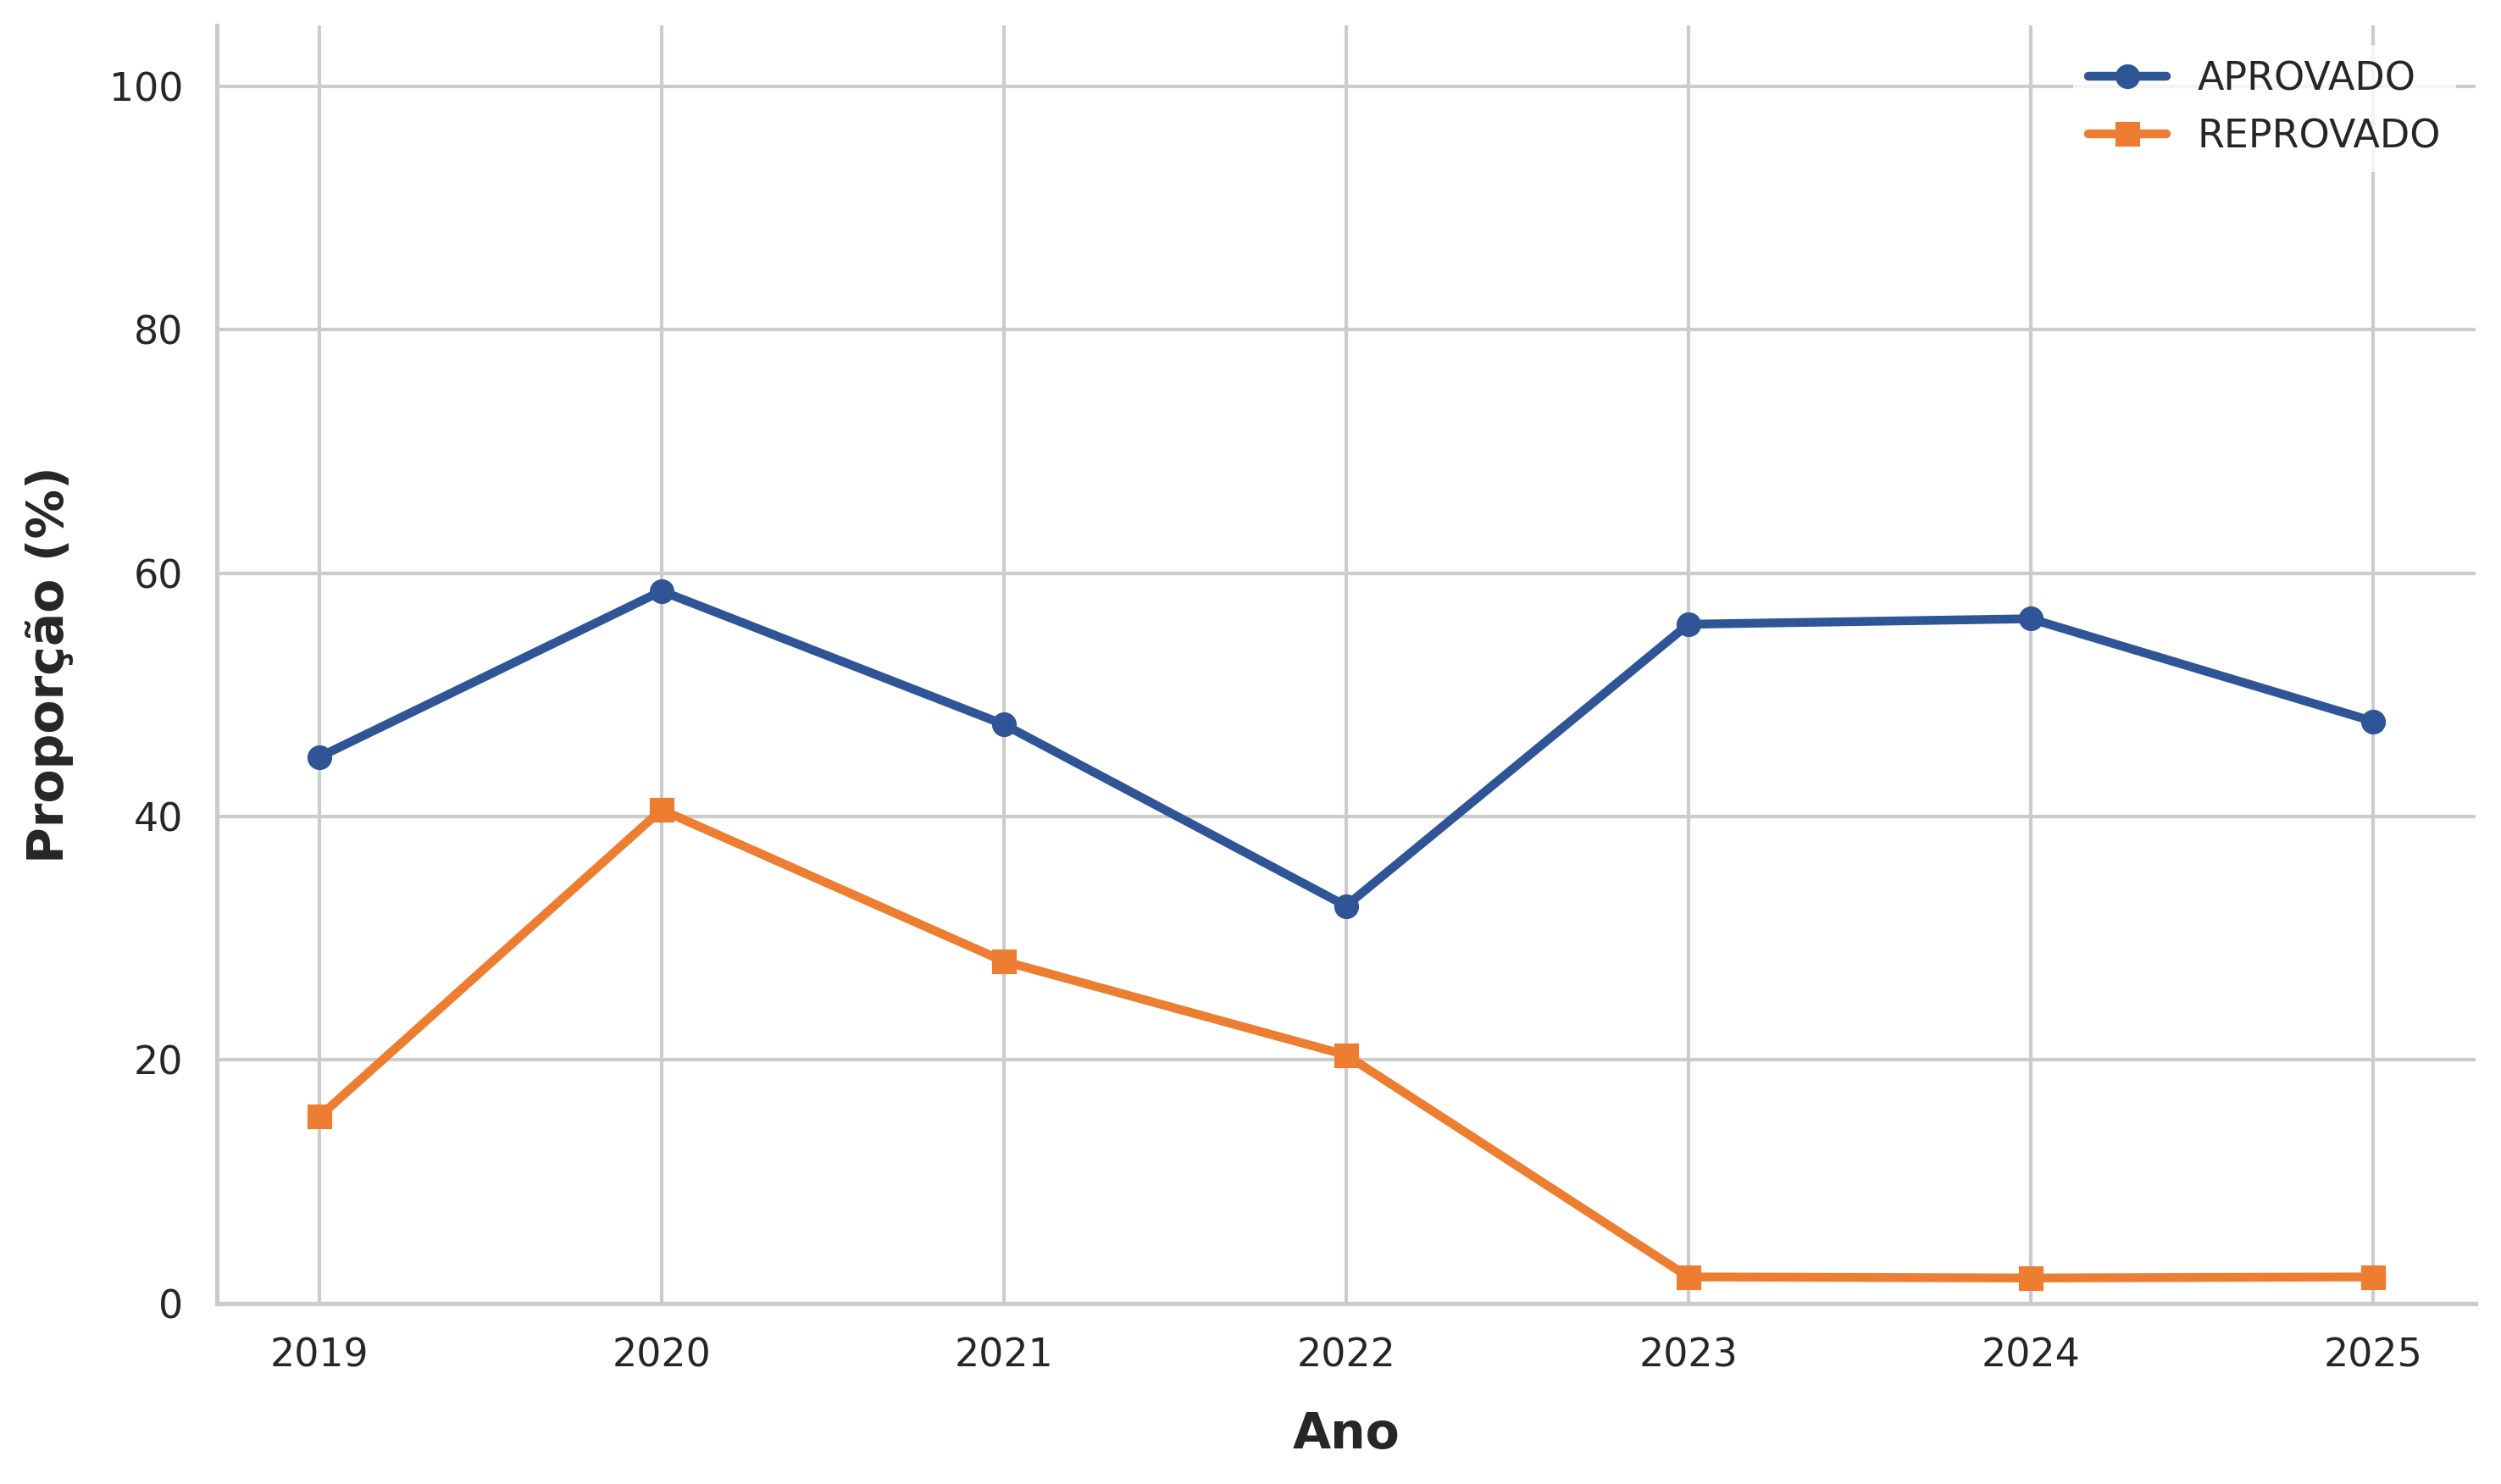

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo para artigo
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 12,          # Tamanho da fonte ideal para leitura
    'axes.labelsize': 14,     # Tamanho dos rótulos dos eixos
    'axes.titlesize': 14,     # Tamanho do título
    'xtick.labelsize': 11,    # Tamanho dos números do eixo X
    'ytick.labelsize': 11,    # Tamanho dos números do eixo Y
    'figure.titlesize': 16
})

# 1. Definindo o tamanho da figura (proporção ideal para páginas de artigos)
plt.figure(figsize=(10, 6), dpi=300) # 300 DPI é o padrão exigido por revistas científicas

# 2. Criando as linhas com as cores exatas solicitadas
plt.plot(df_proporcao['Ano'], df_proporcao['APR'],
         color='#2f5597', label='APROVADO', linewidth=2.5, marker='o')

plt.plot(df_proporcao['Ano'], df_proporcao['REP'],
         color='#ed7d31', label='REPROVADO', linewidth=2.5, marker='s')

# 3. Configurações dos eixos (Ajuste os nomes 'Eixo X' e 'Porcentagem (%)' se precisar)
plt.xlabel('Ano', fontweight='bold', labelpad=10)
plt.ylabel('Proporção (%)', fontweight='bold', labelpad=10)

# Garantir que o eixo X mostre os anos corretamente sem decimais quebrados
plt.xticks(df_proporcao['Ano'].astype(int))

# Limitar o eixo Y de 0 a 100 já que estamos lidando com proporções/porcentagens
plt.ylim(0, 105)

# 4. Legenda e Layout
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
sns.despine() # Remove as bordas superior e direita para um visual mais moderno
plt.tight_layout()

# 5. Salvar o gráfico em alta definição para o seu artigo
# Arquivos .pdf ou .eps são os melhores para artigos pois não perdem qualidade ao dar zoom
#plt.savefig('grafico_artigo.pdf', format='pdf', bbox_inches='tight')

# Exibir na tela
plt.show()

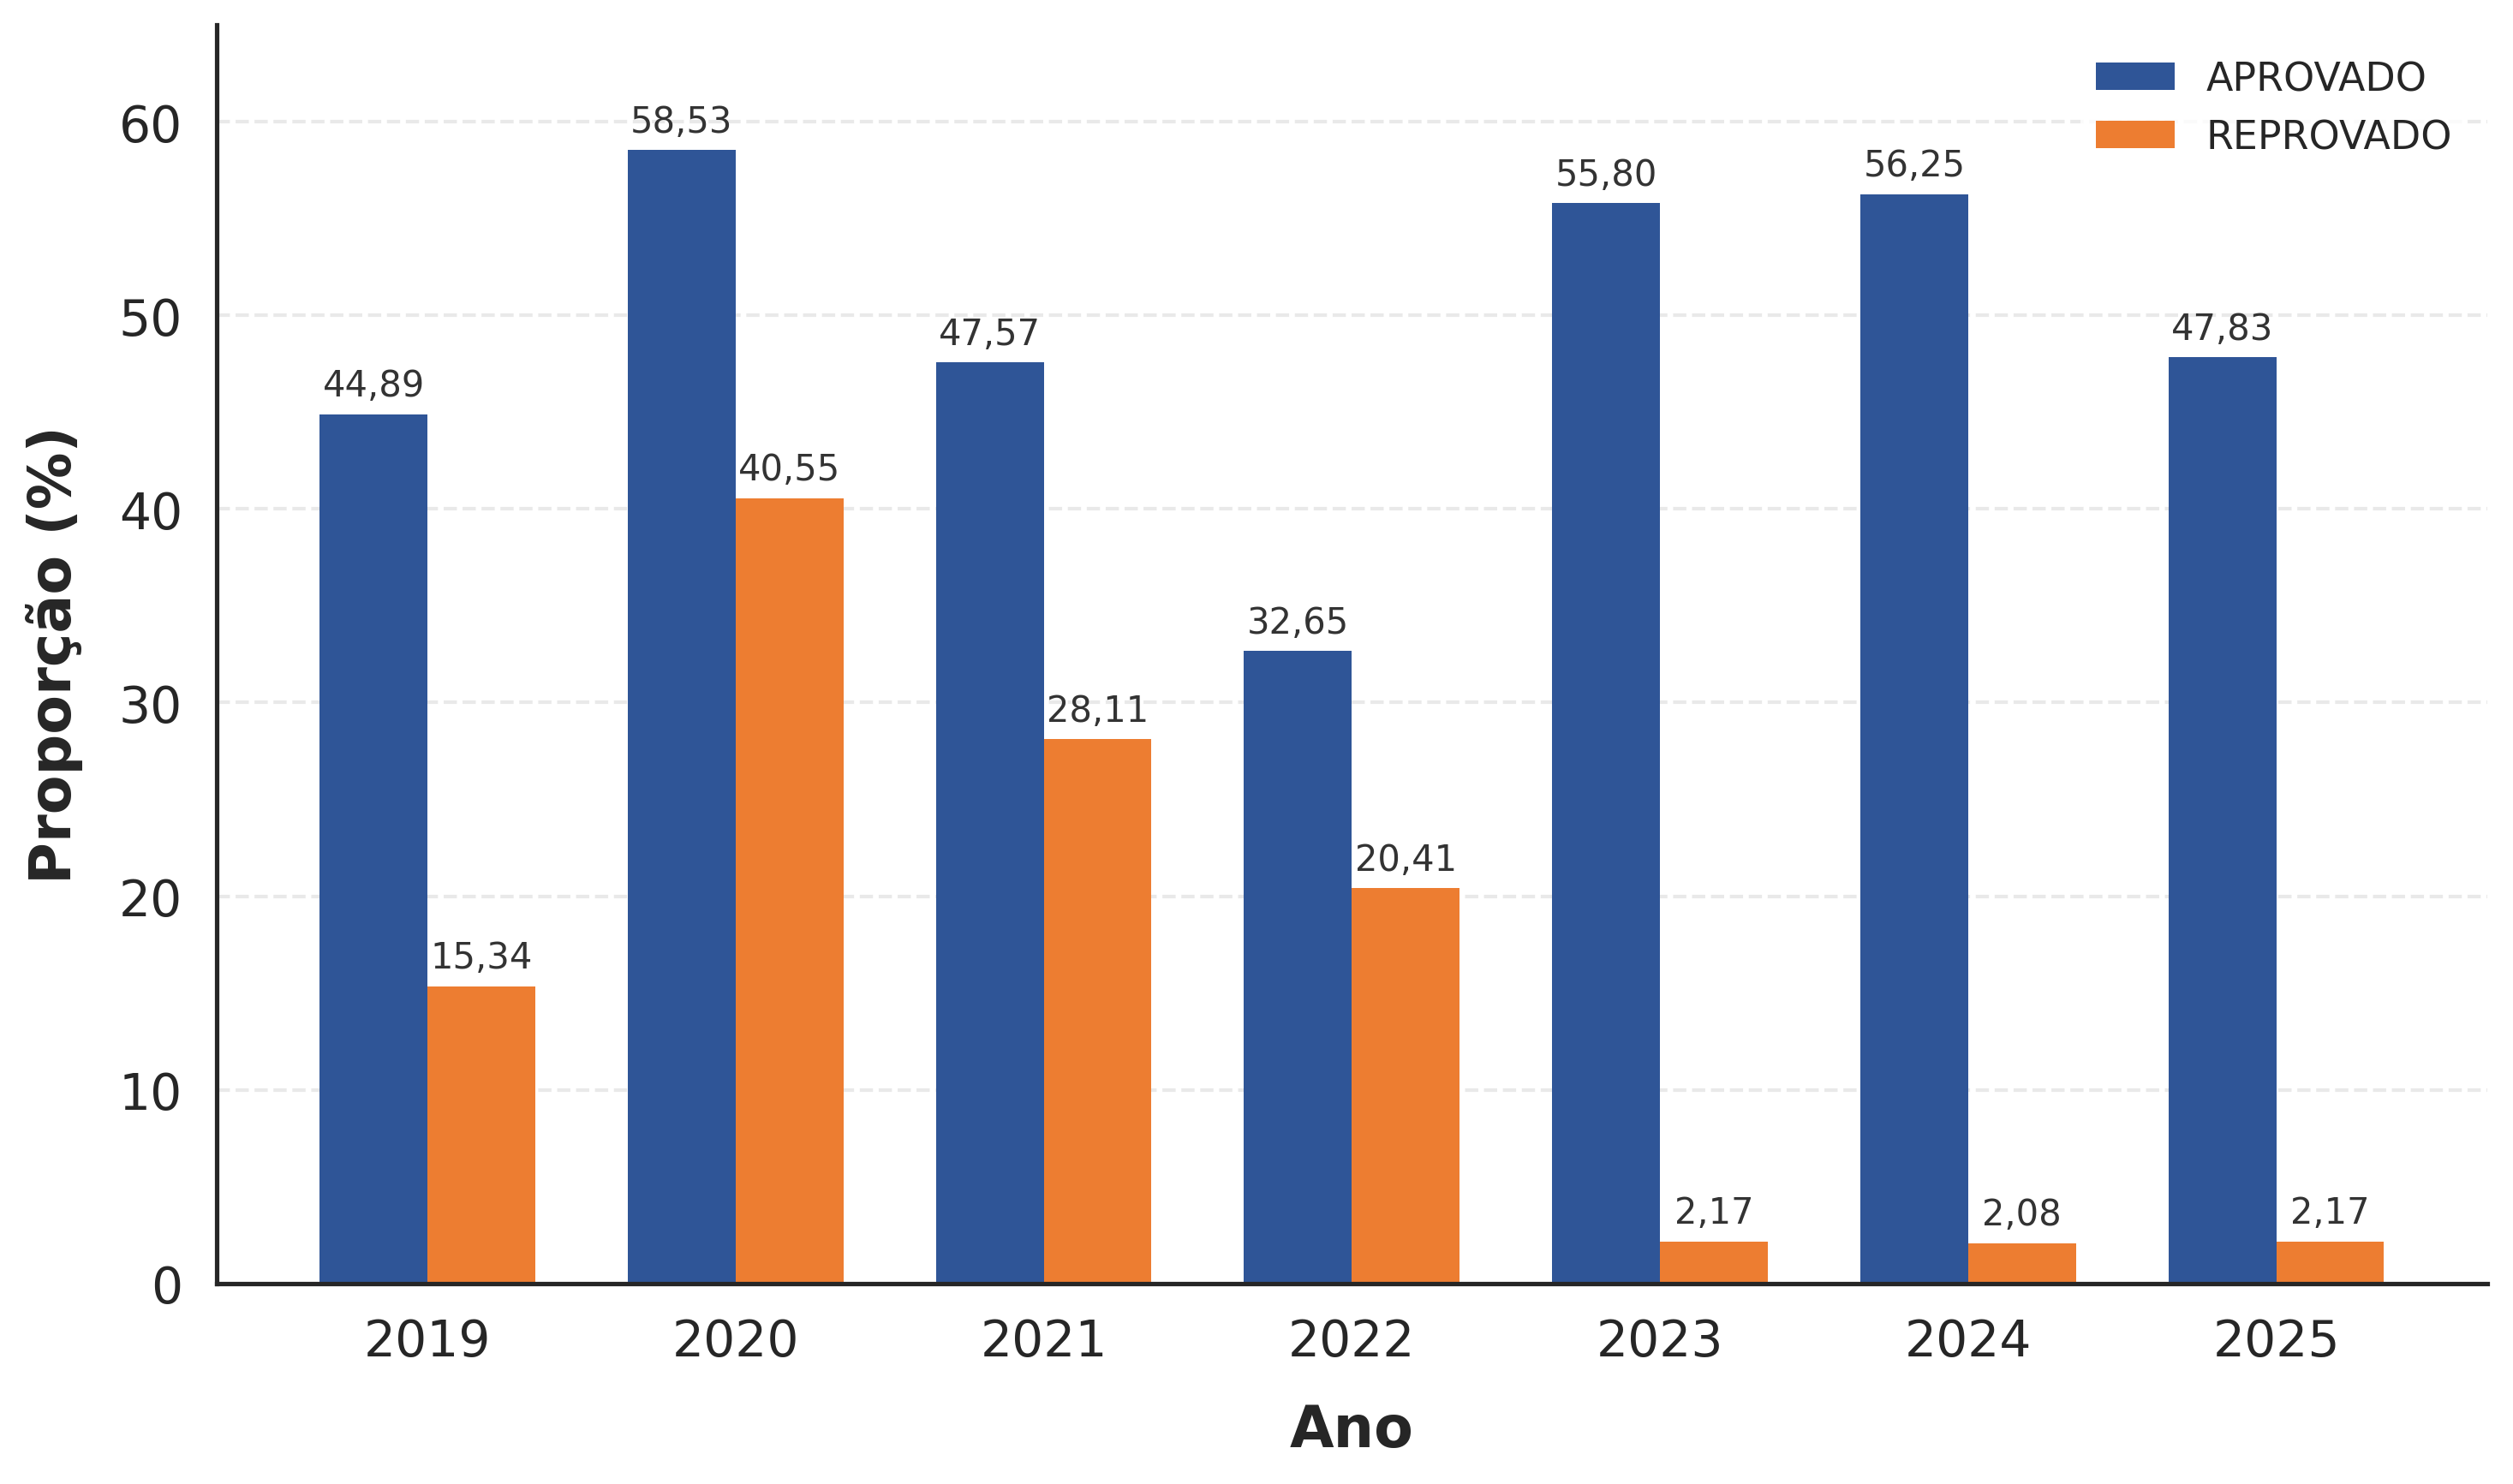

In [47]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo para artigo científico
sns.set_theme(style="white") #whitegrid
plt.rcParams.update({
    'font.size': 14,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
})

# 1. Definindo as posições das barras no eixo X
x = np.arange(len(df_proporcao['Ano']))  # Localização dos grupos de anos
largura_barra = 0.35                      # Largura de cada barra individual

# 2. Criando a figura em alta resolução (300 DPI)
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

# Ativa APENAS as linhas de grade horizontais (eixo Y) com estilo sutil para artigo
#ax.grid(axis='x', linestyle='--', alpha=0.7, color='#e0e0e0', zorder=0)
ax.grid(axis='y', linestyle='--', alpha=0.7, color='#e0e0e0', zorder=0)

# 3. Desenhando as barras lado a lado com as cores exatas
barras1 = ax.bar(x - largura_barra/2, df_proporcao['APR'], largura_barra,
                 label='APROVADO', color='#2f5597', edgecolor='black', linewidth=0.0)

barras2 = ax.bar(x + largura_barra/2, df_proporcao['REP'], largura_barra,
                 label='REPROVADO', color='#ed7d31', edgecolor='black', linewidth=0.0)

# 3.1 Exibe os valores sobre as barras, com vírgula decimal
rotulos_apr = [f'{v:.2f}'.replace('.', ',') for v in df_proporcao['APR']]
rotulos_rep = [f'{v:.2f}'.replace('.', ',') for v in df_proporcao['REP']]

ax.bar_label(barras1, labels=rotulos_apr, padding=3, fontsize=10, color='#333333') #2f5597
ax.bar_label(barras2, labels=rotulos_rep, padding=3, fontsize=10, color='#333333') #ed7d31

# 4. Ajustes dos eixos e rótulos
ax.set_xlabel('Ano', fontweight='bold', labelpad=10)
ax.set_ylabel('Proporção (%)', fontweight='bold', labelpad=10)

# Substitui os índices numéricos pelos anos reais no eixo X
ax.set_xticks(x)
ax.set_xticklabels(df_proporcao['Ano'].astype(int))

# Limita o eixo Y para dar folga no topo para a legenda ou rótulos
ax.set_ylim(0, 65)

# 5. Legenda e acabamento
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
sns.despine() # Remove as bordas superior e direita para um visual limpo
plt.tight_layout()

# 6. Salvar em vetor (.pdf) para garantir qualidade máxima na publicação
plt.savefig(os.path.join(path, 'grafico_apr_rep_anual.pdf'), format='pdf', bbox_inches='tight')
plt.savefig('grafico_apr_rep_anual.png', format='png', dpi=300, bbox_inches='tight')
path_img = os.path.join(path, 'grafico_apr_rep_anual.png')
plt.savefig(path_img, format='png', dpi=300, bbox_inches='tight')

# Exibir gráfico
plt.show()

In [20]:
# 1. Cria uma cópia independente de df_anual
df_taxas = df_anual.copy()

# 2. Calcula as taxas em porcentagem conforme as fórmulas solicitadas
df_taxas['Taxa_APR'] = (df_taxas['APR'] / (df_taxas['APR'] + df_taxas['REP'])) * 100
df_taxas['Taxa_REP'] = (df_taxas['REP'] / (df_taxas['REP'] + df_taxas['APR'])) * 100

# Exibe o novo DataFrame
print(df_taxas)

    Ano    APR   REP  REPMF  Total   Taxa_APR   Taxa_REP
0  2019   79.0  27.0   70.0  176.0  74.528302  25.471698
1  2020  127.0  88.0    2.0  217.0  59.069767  40.930233
2  2021   88.0  52.0   45.0  185.0  62.857143  37.142857
3  2022   32.0  20.0   46.0   98.0  61.538462  38.461538
4  2023   77.0   3.0   58.0  138.0  96.250000   3.750000
5  2024   54.0   2.0   40.0   96.0  96.428571   3.571429
6  2025   44.0   2.0   46.0   92.0  95.652174   4.347826


# Para calcular a o valor esperado pelo Q-quiquadrado

In [22]:
# 1. Cria uma cópia independente de df_anual
df_calc = df_anual.copy()

# 1. Criamos uma coluna de agrupamento para definir os blocos de anos
def mapear_periodo(ano):
    if 2019 <= ano <= 2022:
        return '2019-2022'
    elif ano == 2023:
        return '2023'
    elif 2024 <= ano <= 2025:
        return '2024-2025'
    return 'Outros'

# Adiciona a coluna temporária de período baseada nas regras acima
df_calc['Periodo'] = df_calc['Ano'].apply(mapear_periodo)

print(df_calc)

    Ano    APR   REP  REPMF  Total    Periodo
0  2019   79.0  27.0   70.0  176.0  2019-2022
1  2020  127.0  88.0    2.0  217.0  2019-2022
2  2021   88.0  52.0   45.0  185.0  2019-2022
3  2022   32.0  20.0   46.0   98.0  2019-2022
4  2023   77.0   3.0   58.0  138.0       2023
5  2024   54.0   2.0   40.0   96.0  2024-2025
6  2025   44.0   2.0   46.0   92.0  2024-2025


In [23]:
# 2. Agrega os valores brutos (col1, col2, col3) somando-os por período
# Nota: Não podemos somar as taxas antigas diretamente, precisamos somar o bruto primeiro!
df_agregado = df_calc.groupby('Periodo', as_index=False)[['APR', 'REP', 'REPMF']].sum().reset_index(drop=True)

# 3. Total das anteriores Adicionando a nova coluna com o total da soma linha por linha
df_agregado['Total_APR_REP'] = df_agregado['APR'] + df_agregado['REP']

print(df_agregado)

     Periodo    APR    REP  REPMF  Total_APR_REP
0  2019-2022  326.0  187.0  163.0          513.0
1       2023   77.0    3.0   58.0           80.0
2  2024-2025   98.0    4.0   86.0          102.0


In [24]:
# Cria o novo DataFrame com as proporções da coluna por Periodo

# 1. Selecionamos apenas as colunas que queremos calcular a proporção
colunas_alvo = [col for col in df_agregado.columns if col not in ['Periodo', 'Total_APR_REP']]

# 2. Criamos o novo DataFrame dividindo as colunas pela coluna 'total'
df_agregado_proporcao = df_agregado[colunas_alvo].div(df_agregado['Total_APR_REP'], axis=0) * 100

# 3. Inserimos a coluna 'ano' na primeira posição (índice 0)
df_agregado_proporcao.insert(0, 'Periodo', df_agregado['Periodo'])

# 4. Criamos/Atualizamos a coluna 'total' no final com o valor fixo de 100
df_agregado_proporcao['Total_APR_REP'] = 100

print(df_agregado_proporcao)

     Periodo        APR        REP      REPMF  Total_APR_REP
0  2019-2022  63.547758  36.452242  31.773879            100
1       2023  96.250000   3.750000  72.500000            100
2  2024-2025  96.078431   3.921569  84.313725            100


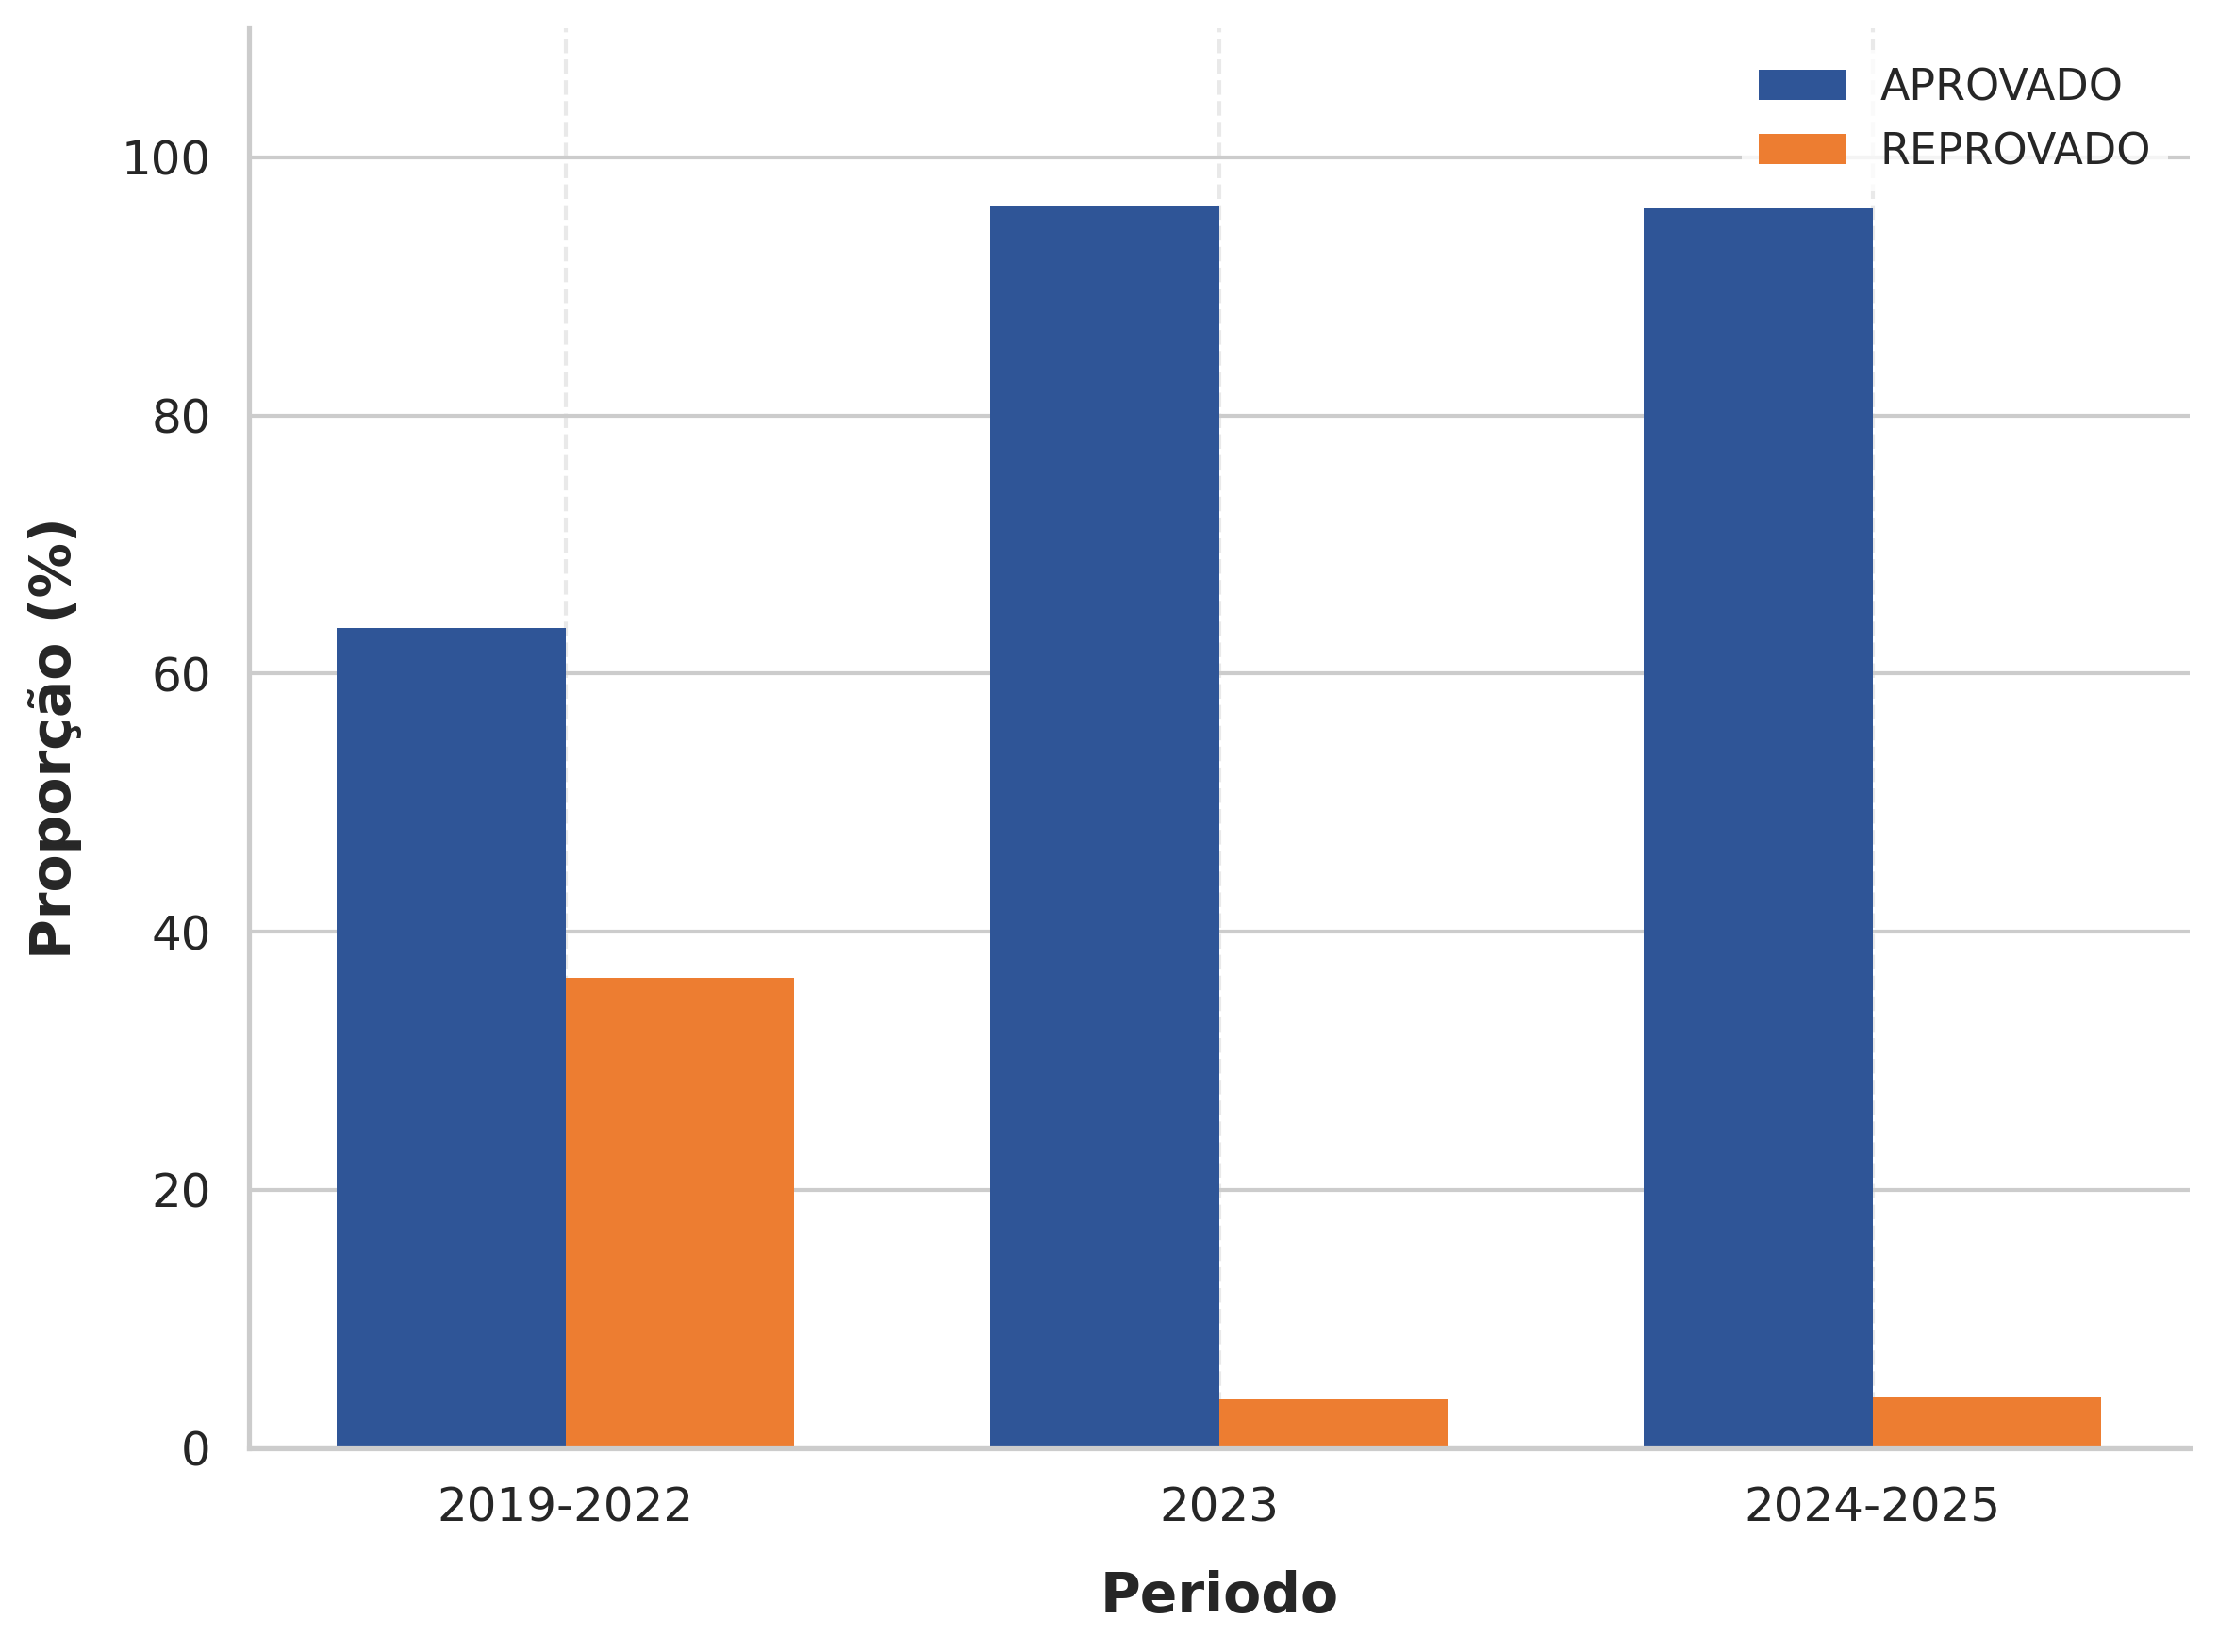

In [25]:
# Configuração de estilo para artigo científico
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})

# 1. Definindo as posições das barras no eixo X
x = np.arange(len(df_agregado_proporcao['Periodo']))  # Localização dos grupos de anos
largura_barra = 0.35                      # Largura de cada barra individual

# 2. Criando a figura em alta resolução (300 DPI)
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Ativa APENAS as linhas de grade horizontais (eixo Y) com estilo sutil para artigo
ax.grid(axis='x', linestyle='--', alpha=0.7, color='#e0e0e0', zorder=0)

# 3. Desenhando as barras lado a lado com as cores exatas
barras1 = ax.bar(x - largura_barra/2, df_agregado_proporcao['APR'], largura_barra,
                 label='APROVADO', color='#2f5597', edgecolor='black', linewidth=0.0)

barras2 = ax.bar(x + largura_barra/2, df_agregado_proporcao['REP'], largura_barra,
                 label='REPROVADO', color='#ed7d31', edgecolor='black', linewidth=0.0)

# 4. Ajustes dos eixos e rótulos
ax.set_xlabel('Periodo', fontweight='bold', labelpad=10)
ax.set_ylabel('Proporção (%)', fontweight='bold', labelpad=10)

# Substitui os índices numéricos pelos anos reais no eixo X
ax.set_xticks(x)
ax.set_xticklabels(df_agregado_proporcao['Periodo'])

# Limita o eixo Y para dar folga no topo para a legenda ou rótulos
ax.set_ylim(0, 110)

# 5. Legenda e acabamento
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
sns.despine() # Remove as bordas superior e direita para um visual limpo
plt.tight_layout()

# 6. Salvar em vetor (.pdf) para garantir qualidade máxima na publicação
#plt.savefig('grafico_barras_artigo.pdf', format='pdf', bbox_inches='tight')

# Exibir gráfico
plt.show()

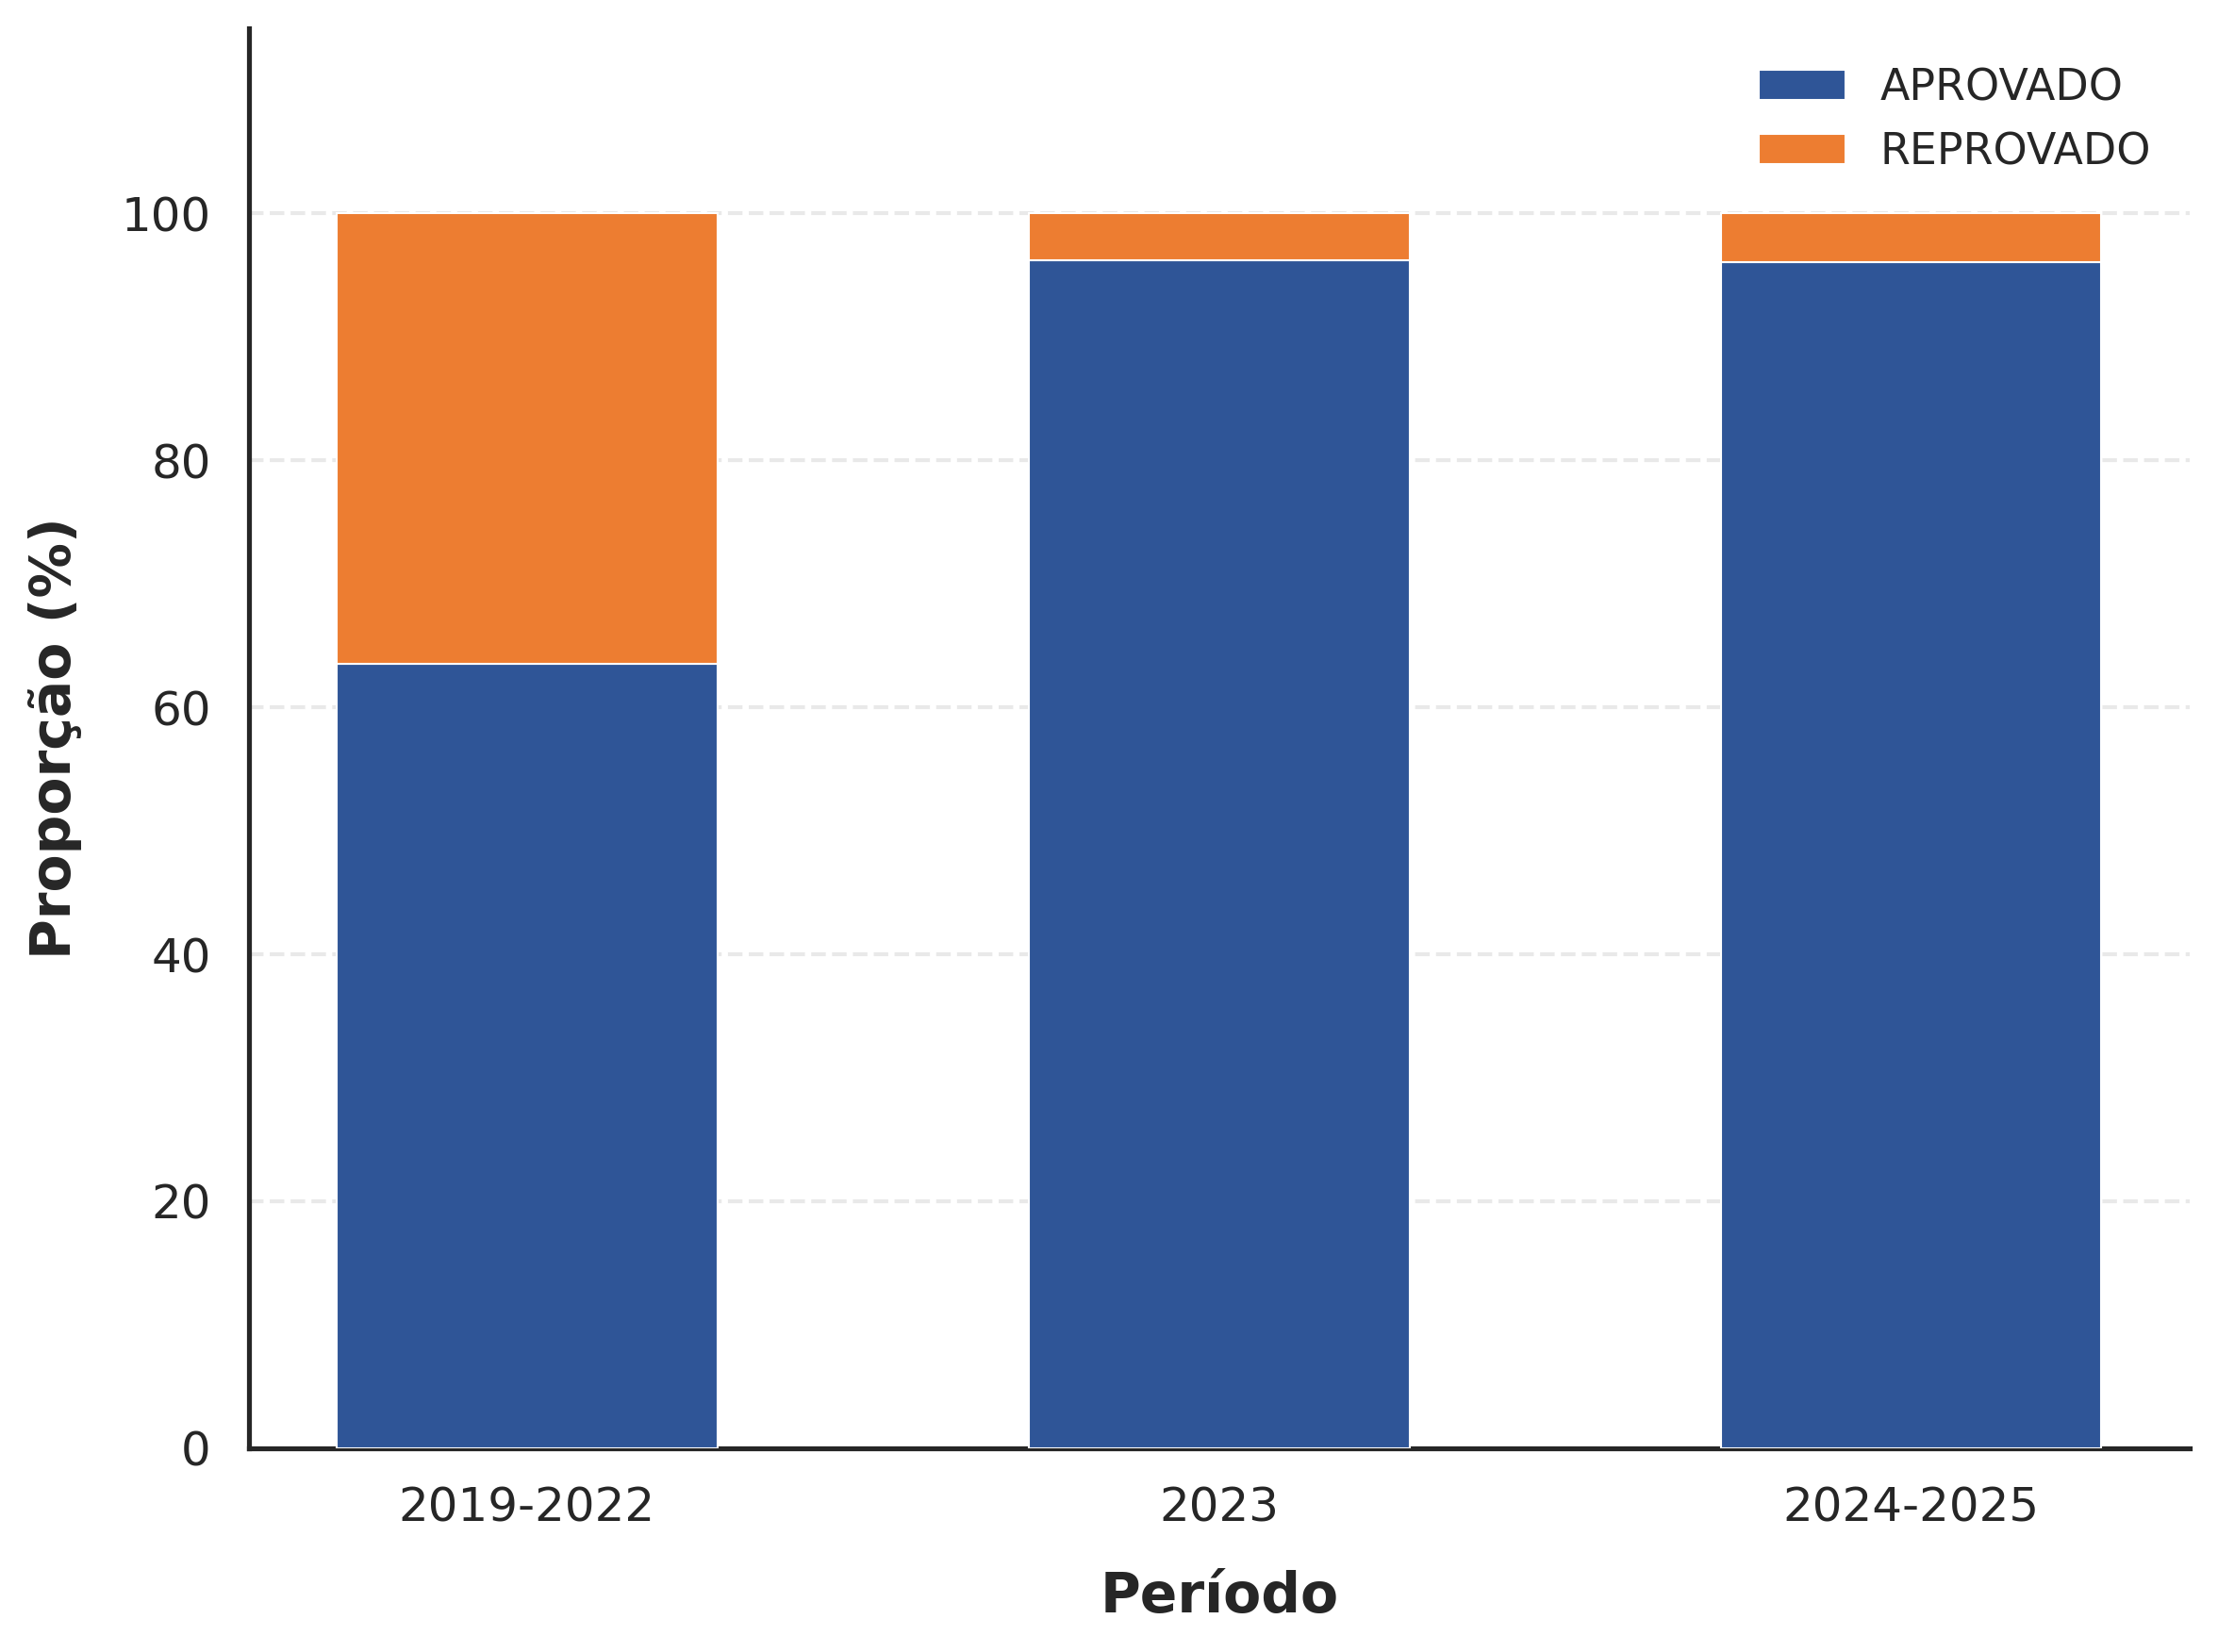

In [46]:
# Configuração de estilo para artigo científico
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})

# 1. Definindo as posições das barras no eixo X
x = np.arange(len(df_agregado_proporcao['Periodo']))  # Localização dos grupos de anos
largura_barra = 0.55                      # Largura ligeiramente maior fica melhor visualmente em barras empilhadas

# 2. Criando a figura em alta resolução (300 DPI)
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Ativa APENAS as linhas de grade horizontais (eixo Y) com estilo sutil para artigo
# Nota: Como o seu comentário dizia "linhas horizontais (eixo Y)", o correto é usar axis='y'
ax.grid(axis='y', linestyle='--', alpha=0.7, color='#e0e0e0', zorder=0)

# 3. Desenhando as barras EMPILHADAS (uma sobre a outra)
# A primeira barra é desenhada normalmente na posição 'x'
barras1 = ax.bar(x, df_agregado_proporcao['APR'], largura_barra,
                 label='APROVADO', color='#2f5597', linewidth=0.5, zorder=3)

# A segunda barra usa o parâmetro 'bottom' para empilhar sobre a primeira
barras2 = ax.bar(x, df_agregado_proporcao['REP'], largura_barra,
                 bottom=df_agregado_proporcao['APR'],
                 label='REPROVADO', color='#ed7d31', linewidth=0.5, zorder=3)

# 4. Ajustes dos eixos e rótulos
ax.set_xlabel('Período', fontweight='bold', labelpad=10)
ax.set_ylabel('Proporção (%)', fontweight='bold', labelpad=10)

# Substitui os índices numéricos pelos anos reais no eixo X
ax.set_xticks(x)
ax.set_xticklabels(df_agregado_proporcao['Periodo'])

# Limita o eixo Y em 100% (já que é uma proporção empilhada) com uma leve folga para a legenda
ax.set_ylim(0, 115)

# 5. Legenda e acabamento
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
sns.despine() # Remove as bordas superior e direita para um visual limpo
plt.tight_layout()

# 6. Salvar em vetor (.pdf) para garantir qualidade máxima na publicação
plt.savefig(os.path.join(path, 'grafico_barras_empilhadas.pdf'), format='pdf', bbox_inches='tight')
plt.savefig('grafico_barras_empilhadas.png', format='png', dpi=300, bbox_inches='tight')
path_img = os.path.join(path, 'grafico_barras_empilhadas.png')
plt.savefig(path_img, format='png', dpi=300, bbox_inches='tight')

# Exibir gráfico
plt.show()

### Teste do Qui-Quadrado de Independência ($\chi^2$)

O teste do Qui-Quadrado de Independência é aplicado aos valores absolutos de `col1` e `col2` nos três períodos analíticos, excluindo-se a linha de totalização. O objetivo é avaliar se existe associação estatisticamente significativa entre a categoria observada e o período analisado. O cálculo é realizado em Python com a função `chi2_contingency`, da biblioteca `scipy`, obtendo-se a estatística $\chi^2$, os graus de liberdade e o p-valor.

In [29]:
import scipy.stats as stats

# 1. Filtro no DataFrame agregado para pegar apenas as linhas dos períodos (excluindo o 'Total')
df_teste = df_agregado.drop(columns=['Total_APR_REP'])

print(df_teste)

     Periodo    APR    REP  REPMF
0  2019-2022  326.0  187.0  163.0
1       2023   77.0    3.0   58.0
2  2024-2025   98.0    4.0   86.0


In [30]:
# 2. Construção da tabela de contingência usando apenas as frequências absolutas (valores brutos)
tabela_contingencia = df_teste[['APR', 'REP']].to_numpy()

print(tabela_contingencia)


[[326. 187.]
 [ 77.   3.]
 [ 98.   4.]]


In [31]:
# 3. Aplicar o Teste do Qui-Quadrado de Independência
chi2, p_valor, graus_liberdade, frequencias_esperadas = stats.chi2_contingency(tabela_contingencia)

# 4. Exibir os resultados formatados para o padrão de artigos científicos
print("--- RESULTADO DO TESTE QUI-QUADRADO ---")
print(f"Estatística Qui-Quadrado (χ²): {chi2:.4f}")
print(f"Graus de Liberdade (gl): {graus_liberdade}")
print(f"p-valor: {p_valor:.4e}")  # Exibe em notação científica para alta precisão

# 5. Regra de decisão básica para o texto do seu artigo
alfa = 0.05
if p_valor < alfa:
    print("\nConclusão: Existe uma associação estatisticamente significativa entre as colunas e os períodos (p < 0.05).")
else:
    print("\nConclusão: Não há evidências de associação estatisticamente significativa (p >= 0.05).")

--- RESULTADO DO TESTE QUI-QUADRADO ---
Estatística Qui-Quadrado (χ²): 70.9799
Graus de Liberdade (gl): 2
p-valor: 3.8628e-16

Conclusão: Existe uma associação estatisticamente significativa entre as colunas e os períodos (p < 0.05).


## Calcular o V de Cramér (que mede a força da associação estatística)

O V de Cramér quantifica a intensidade da associação entre as variáveis categóricas, complementando o teste do Qui-Quadrado ($\chi^2$). Seu valor varia de 0 a 1, em que valores próximos de 0 indicam associação fraca ou inexistente, enquanto valores próximos de 1 indicam associação mais forte.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# 1. CÁLCULO DO V DE CRAMER
# Filtrar o DataFrame removendo a linha 'Total' para análise estatística
df_estatistica = df_agregado.drop(columns=['Total_APR_REP'])
tabela_contingencia = df_estatistica[['APR', 'REP']].to_numpy()

print(df_estatistica)

tabela_contingencia

# Executar novamente o qui-quadrado para coletar as variáveis do cálculo do V
chi2, p_valor, gl, _ = stats.chi2_contingency(tabela_contingencia)
n_total = tabela_contingencia.sum()              # Número total de observações
min_dim = min(tabela_contingencia.shape) - 1     # Menor dimensão da tabela (linhas-1 ou colunas-1)

# Fórmula do V de Cramer
v_cramer = np.sqrt(chi2 / (n_total * min_dim))

print("--- MEDIDA DE ASSOCIAÇÃO ---")
print(f"V de Cramer: {v_cramer:.4f}")


     Periodo    APR    REP  REPMF
0  2019-2022  326.0  187.0  163.0
1       2023   77.0    3.0   58.0
2  2024-2025   98.0    4.0   86.0
--- MEDIDA DE ASSOCIAÇÃO ---
V de Cramer: 0.3196


<>:42: SyntaxWarning: invalid escape sequence '\c'
<>:42: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1099/1532133069.py:42: SyntaxWarning: invalid escape sequence '\c'
  texto_completo = f"Teste $\chi^2$\n{texto_p}\nV de Cramer = {v_cramer:.3f}"


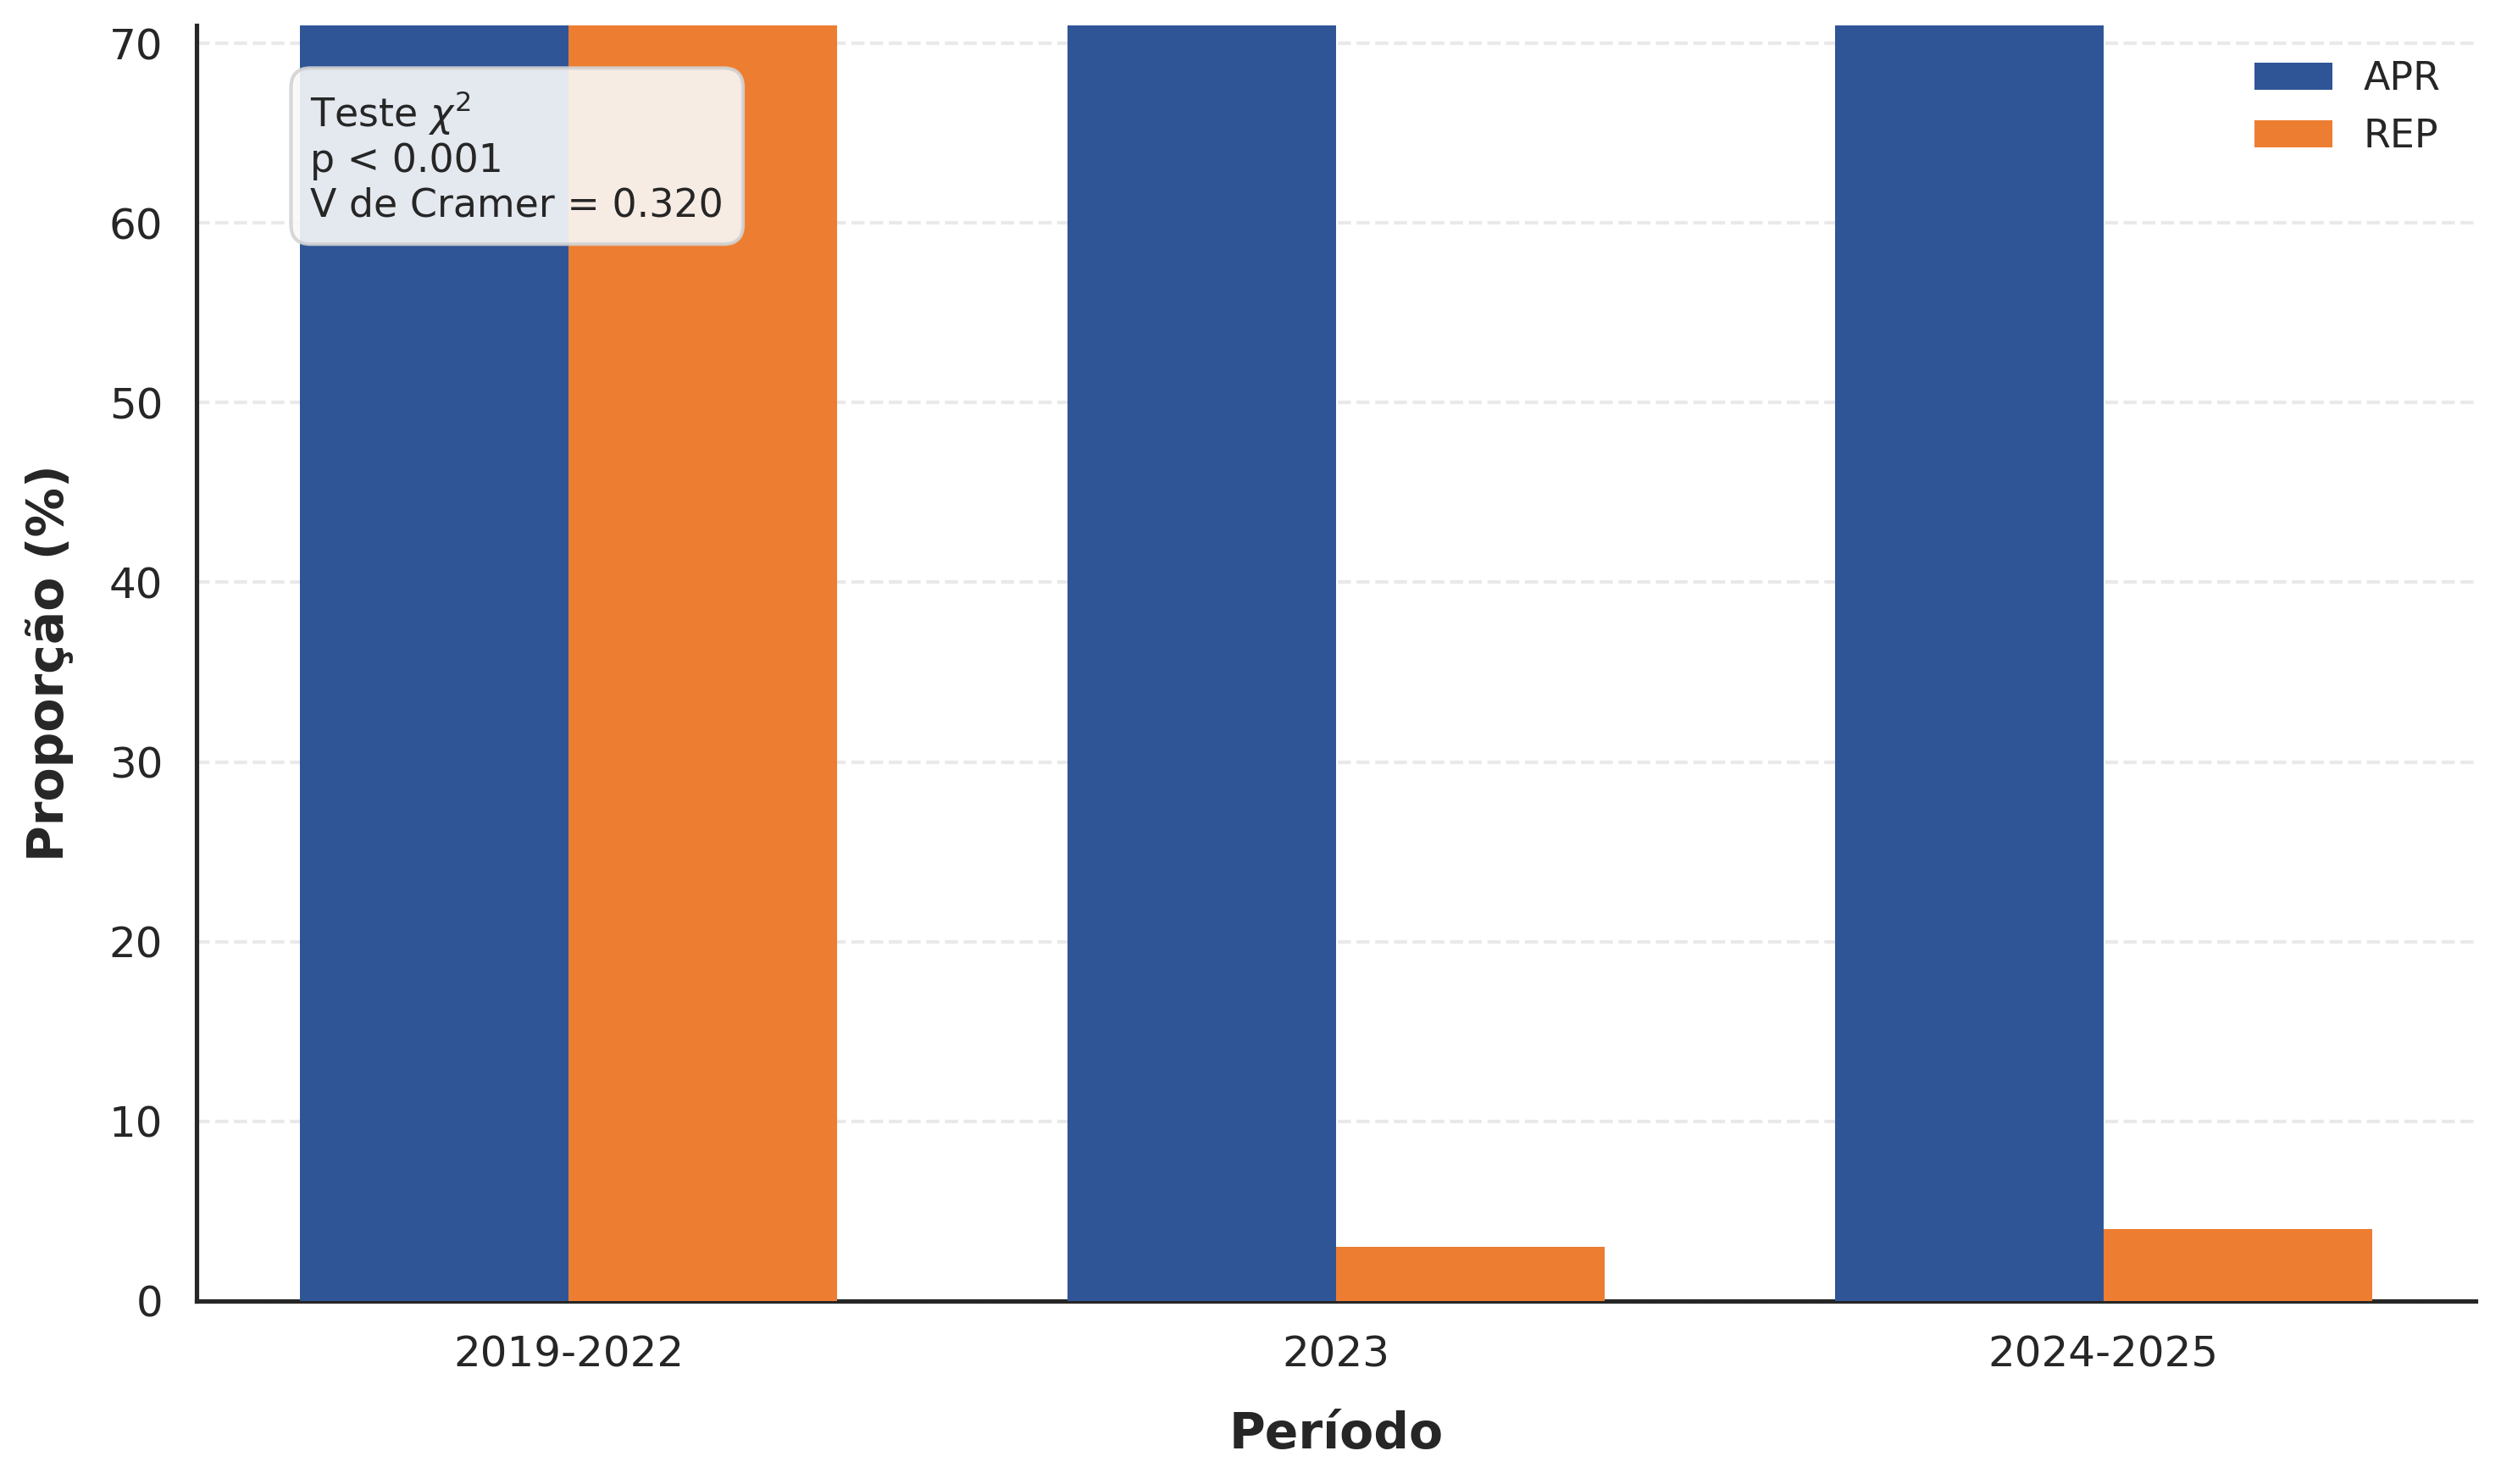

In [34]:
# 2. CONFIGURAÇÃO E GERAÇÃO DO GRÁFICO
sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})

# Configuração de posições e eixos com os dados agrupados (excluindo o 'Total')
x = np.arange(len(df_estatistica['Periodo']))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

# Grade apenas horizontal
ax.grid(axis='y', linestyle='--', alpha=0.7, color='#e0e0e0', zorder=0)

# Barras lado a lado usando as taxas calculadas
barras1 = ax.bar(x - largura_barra/2, df_estatistica['APR'], largura_barra,
                 label='APR', color='#2f5597', edgecolor='black', linewidth=0.0, zorder=3)

barras2 = ax.bar(x + largura_barra/2, df_estatistica['REP'], largura_barra,
                 label='REP', color='#ed7d31', edgecolor='black', linewidth=0.0, zorder=3)

# Ajustes de eixos e rótulos
ax.set_xlabel('Período', fontweight='bold', labelpad=10)
ax.set_ylabel('Proporção (%)', fontweight='bold', labelpad=10)
ax.set_xticks(x)
ax.set_xticklabels(df_estatistica['Periodo'])

# Limite estrito do eixo Y em 70 como você pediu anteriormente
ax.set_ylim(0, 71)
ax.set_yticks(np.arange(0, 71, 10))

# Legenda posicionada de forma limpa
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# ANOTAÇÃO DO P-VALOR E DO V DE CRAMER
# Formata o p-valor para exibição acadêmica padrão (ex: p < 0.001 ou valor exato)
texto_p = f"p < 0.001" if p_valor < 0.001 else f"p = {p_valor:.3f}"
texto_completo = f"Teste $\chi^2$\n{texto_p}\nV de Cramer = {v_cramer:.3f}"

# Insere a caixa de texto informativa no canto superior esquerdo do gráfico
ax.text(0.05, 0.95, texto_completo, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f9f9f9', edgecolor='#d3d3d3', alpha=0.9))

sns.despine()
plt.tight_layout()

# Salva a imagem em alta resolução e formato vetorial para publicação
#plt.savefig('grafico_artigo_final.pdf', format='pdf', bbox_inches='tight')
plt.show()

## Teste de Tendência de Cochran–Armitage

O teste de Cochran–Armitage avalia se a proporção de reprovação (REP) apresenta uma tendência linear estatisticamente significativa ao longo das fases temporais ordenadas (2019–2022, 2023 e 2024–2025). Diferentemente do teste do Qui-Quadrado de Independência, esse método considera a ordem temporal das fases, permitindo identificar tendências crescentes ou decrescentes na proporção de reprovação.

In [35]:
import numpy as np
from scipy.stats import norm

# 1. Reaproveita o df_agregado já calculado (Periodo, APR, REP, REPMF)
df_tendencia = df_agregado.drop(columns=['Total_APR_REP']).copy()

# 2. Atribui um escore ordinal a cada fase, respeitando a ordem cronológica
escore_periodo = {'2019-2022': 1, '2023': 2, '2024-2025': 3}
df_tendencia['Escore'] = df_tendencia['Periodo'].map(escore_periodo)

print(df_tendencia)

# 3. Variáveis do teste
n = df_tendencia['APR'] + df_tendencia['REP']   # estudantes ativos por fase
r = df_tendencia['REP']                          # reprovados por desempenho (evento de interesse)
x = df_tendencia['Escore']                       # escore ordinal da fase

n_total = n.sum()
p_barra = r.sum() / n_total

# 4. Estatística do teste de Cochran-Armitage
numerador = np.sum(n * x * (r / n - p_barra))
denominador = np.sqrt(
    p_barra * (1 - p_barra) * (np.sum(n * x**2) - (np.sum(n * x))**2 / n_total)
)

z = numerador / denominador
p_valor_tendencia = 2 * (1 - norm.cdf(abs(z)))  # teste bicaudal

# 5. Exibe os resultados formatados para o artigo
print("\n--- RESULTADO DO TESTE DE TENDÊNCIA DE COCHRAN-ARMITAGE ---")
print(f"Estatística Z: {z:.4f}")
print(f"p-valor: {p_valor_tendencia:.4e}")

if p_valor_tendencia < 0.05:
    sentido = "decrescente" if z < 0 else "crescente"
    print(f"\nConclusão: há tendência {sentido} estatisticamente significativa na proporção de reprovação ao longo das fases (p < 0,05).")
else:
    print("\nConclusão: não há evidências de tendência linear estatisticamente significativa (p >= 0,05).")


     Periodo    APR    REP  REPMF  Escore
0  2019-2022  326.0  187.0  163.0       1
1       2023   77.0    3.0   58.0       2
2  2024-2025   98.0    4.0   86.0       3

--- RESULTADO DO TESTE DE TENDÊNCIA DE COCHRAN-ARMITAGE ---
Estatística Z: -7.8920
p-valor: 2.8866e-15

Conclusão: há tendência decrescente estatisticamente significativa na proporção de reprovação ao longo das fases (p < 0,05).


# Análise complementar por turno (Integral × Noturno)

O turno é identificado pela letra do código de horário do SIGAA: **N** indica turma noturna; **M** ou **T** indicam turma do turno integral.

A análise complementa, sem substituir, a análise geral por fase. Os procedimentos são:
1. **Teste de Cochran-Mantel-Haenszel generalizado** (Landis, Heyman e Koch, 1978): verifica se a associação entre fase temporal e situação acadêmica se mantém com o turno controlado.
2. **Teste exato de Fisher** (Fisher, 1922): compara a fase de referência (2019-2022) com as fases posteriores dentro de cada turno, e compara os turnos dentro de cada fase quanto à REP e à REPMF. É usado porque há frequências esperadas inferiores a 5 a partir de 2023.

In [36]:
#display(df)
print(df.columns.tolist())

['Disciplina', 'Ano/Período', 'Código', 'Docente(s)', 'CH Total do Componente', 'Tipo', 'Situação', 'Horário', 'Local', 'Matrículas', 'Capacidade', 'Data Início', 'Data Fim', 'APR', 'REP', 'REPMF', 'Total', 'Ano']


In [37]:
import numpy as np
import pandas as pd
import scipy.stats as stats

# 1. Cópia independente
df_turno = df.copy()

# 2. Garantir que Ano/Período seja datetime
df_turno['Ano/Período'] = pd.to_datetime(
    df_turno['Ano/Período'],
    errors='coerce'
)

# 3. Extrair somente o ano
df_turno['Ano'] = df_turno['Ano/Período'].dt.year

# 4. Excluir 2026
df_turno = df_turno[df_turno['Ano'] != 2026].copy()

# 5. Identificação do turno
df_turno['Turno'] = np.where(
    df_turno['Horário'].astype(str).str.contains(
        r'\d+N\d+',
        regex=True
    ),
    'Noturno',
    'Integral'
)

# 6. Mapear período usando a coluna Ano
df_turno['Periodo'] = df_turno['Ano'].apply(mapear_periodo)

# 7. Conferência
display(df_turno[['Ano/Período', 'Código', 'Horário', 'Turno', 'APR', 'REP', 'REPMF']])

,Ano/Período,Código,Horário,Turno,APR,REP,REPMF
3,2025-02-01,Turma 01,24M23,Integral,0.0,0.0,0.0
4,2025-02-01,Turma 02,24N12,Noturno,4.0,1.0,11.0
5,2025-01-01,Turma 01,4M45 6M23,Integral,16.0,0.0,9.0
6,2025-01-01,Turma 02,4M23 6M45,Integral,0.0,0.0,0.0
7,2025-01-01,Turma 03,4N34 6N12,Noturno,24.0,1.0,26.0
8,2024-03-01,Turma 01,46T1234,Integral,5.0,0.0,1.0
9,2024-03-01,Turma 02,46N1234,Noturno,1.0,0.0,2.0
10,2024-01-01,Turma 01,4M45 6M23,Integral,19.0,0.0,13.0
11,2024-01-01,Turma 02,4M23 6M45,Integral,2.0,0.0,2.0
12,2024-01-01,Turma 03,4N34 6N12,Noturno,27.0,2.0,22.0


In [38]:
# AGREGAÇÃO POR FASE E TURNO
ordem_fases = ['2019-2022', '2023', '2024-2025']
ordem_turnos = ['Integral', 'Noturno']

df_fase_turno = (df_turno.groupby(['Periodo', 'Turno'])[['APR', 'REP', 'REPMF']]
                 .sum()
                 .reindex(pd.MultiIndex.from_product([ordem_fases, ordem_turnos],
                                                     names=['Periodo', 'Turno']))
                 .reset_index())

df_fase_turno['Ativos'] = df_fase_turno['APR'] + df_fase_turno['REP']
df_fase_turno['Total'] = df_fase_turno['Ativos'] + df_fase_turno['REPMF']

# Taxa de reprovação sobre os ativos (mesma fórmula da análise geral)
df_fase_turno['Taxa_REP'] = df_fase_turno['REP'] / df_fase_turno['Ativos'] * 100
# Taxa de REPMF sobre o total de matrículas consolidadas
df_fase_turno['Taxa_REPMF'] = df_fase_turno['REPMF'] / df_fase_turno['Total'] * 100

print(df_fase_turno[['Periodo', 'Turno', 'Ativos', 'APR', 'REP', 'REPMF', 'Taxa_REP', 'Taxa_REPMF']]
      .round(2).to_string(index=False))

  Periodo    Turno  Ativos   APR   REP  REPMF  Taxa_REP  Taxa_REPMF
2019-2022 Integral   350.0 230.0 120.0  114.0     34.29       24.57
2019-2022  Noturno   163.0  96.0  67.0   49.0     41.10       23.11
     2023 Integral    32.0  32.0   0.0   24.0      0.00       42.86
     2023  Noturno    48.0  45.0   3.0   34.0      6.25       41.46
2024-2025 Integral    42.0  42.0   0.0   25.0      0.00       37.31
2024-2025  Noturno    60.0  56.0   4.0   61.0      6.67       50.41


In [40]:
# COMPOSIÇÃO DOS ESTUDANTES ATIVOS POR TURNO EM CADA FASE
composicao = df_fase_turno.pivot(index='Periodo', columns='Turno', values='Ativos').loc[ordem_fases]
composicao['% Noturno'] = composicao['Noturno'] / composicao[ordem_turnos].sum(axis=1) * 100
print(composicao.round(1))

Turno      Integral  Noturno  % Noturno
Periodo                                
2019-2022     350.0    163.0       31.8
2023           32.0     48.0       60.0
2024-2025      42.0     60.0       58.8


## 1. Teste Exato de Fisher: fase de referência × fase posterior, por turno

O teste exato de Fisher é aplicado a uma tabela de contingência 2×2 para cada turno, comparando a fase de referência (2019–2022) com a fase posterior (2023–2025), com base nas frequências absolutas de aprovação (APR) e reprovação (REP). O objetivo é verificar se existe uma associação estatisticamente significativa entre a fase temporal e o resultado acadêmico em cada turno.

In [41]:
def linha(fase, turno, col):
    return df_fase_turno[(df_fase_turno['Periodo'] == fase) &
                         (df_fase_turno['Turno'] == turno)][col].item()

print("--- FISHER: 2019-2022 × 2023-2025, POR TURNO ---")
for turno in ordem_turnos:
    pre = [linha('2019-2022', turno, 'APR'), linha('2019-2022', turno, 'REP')]
    pos = [linha('2023', turno, 'APR') + linha('2024-2025', turno, 'APR'),
           linha('2023', turno, 'REP') + linha('2024-2025', turno, 'REP')]
    tabela = np.array([pre, pos])
    _, p_f = stats.fisher_exact(tabela)
    taxa_pre = pre[1] / sum(pre) * 100
    taxa_pos = pos[1] / sum(pos) * 100
    texto_p = "p < 0,001" if p_f < 0.001 else f"p = {p_f:.3f}"
    print(f"{turno}: REP {taxa_pre:.2f}% → {taxa_pos:.2f}%  |  {texto_p}  (p = {p_f:.2e})")

--- FISHER: 2019-2022 × 2023-2025, POR TURNO ---
Integral: REP 34.29% → 0.00%  |  p < 0,001  (p = 1.41e-12)
Noturno: REP 41.10% → 6.48%  |  p < 0,001  (p = 4.26e-11)


## 2. Teste de Cochran–Mantel–Haenszel generalizado: fase × situação acadêmica, controlando o turno

O teste de Cochran–Mantel–Haenszel generalizado avalia a associação entre a fase temporal e a situação acadêmica (APR/REP), controlando o efeito do turno por meio da estratificação. Cada turno constitui um estrato com uma tabela de contingência 3×2, correspondente às três fases temporais e às duas situações acadêmicas. Sob a hipótese nula de independência condicional, a estatística \(Q\) segue, assintoticamente, uma distribuição qui-quadrado com \((r-1)(c-1)=2\) graus de liberdade.

In [42]:
def cmh_generalizado(tabelas):
    """CMH de associação geral para tabelas IxJ estratificadas (Landis, Heyman e Koch, 1978)."""
    I, J = np.asarray(tabelas[0]).shape
    d = np.zeros((I - 1) * (J - 1))
    V = np.zeros((len(d), len(d)))
    for t in tabelas:
        t = np.asarray(t, dtype=float)
        n = t.sum()
        if n < 2:
            continue
        lin, col = t.sum(axis=1), t.sum(axis=0)
        obs = t[:I-1, :J-1].ravel()
        esp = np.outer(lin[:I-1], col[:J-1]).ravel() / n
        pl, pc = lin / n, col / n
        Vl = np.diag(pl[:I-1]) - np.outer(pl[:I-1], pl[:I-1])
        Vc = np.diag(pc[:J-1]) - np.outer(pc[:J-1], pc[:J-1])
        d += obs - esp
        V += n**2 / (n - 1) * np.kron(Vl, Vc)
    Q = d @ np.linalg.solve(V, d)
    gl = len(d)
    return Q, gl, stats.chi2.sf(Q, gl)

# Tabelas 3x2 (fases x [APR, REP]) para cada turno
tabelas_rep = [df_fase_turno[df_fase_turno['Turno'] == t].set_index('Periodo')
               .loc[ordem_fases, ['APR', 'REP']].to_numpy()
               for t in ordem_turnos]

# Verificação da implementação: com um único estrato, Q = χ² de Pearson × (n-1)/n
tab_unica = tabelas_rep[0] + tabelas_rep[1]
chi2_ref = stats.chi2_contingency(tab_unica)[0]
print(f"Verificação: {cmh_generalizado([tab_unica])[0]:.4f} = {chi2_ref * (tab_unica.sum() - 1) / tab_unica.sum():.4f}\n")

Q_cmh, gl_cmh, p_cmh = cmh_generalizado(tabelas_rep)
print("--- CMH GENERALIZADO: FASE × SITUAÇÃO ACADÊMICA, ESTRATIFICADO POR TURNO ---")
print(f"Q_CMH = {Q_cmh:.2f}; gl = {gl_cmh}; p = {p_cmh:.2e}")
print(f"(Análise geral, não estratificada: χ² = {chi2_ref:.2f})")

Verificação: 70.8778 = 70.8778

--- CMH GENERALIZADO: FASE × SITUAÇÃO ACADÊMICA, ESTRATIFICADO POR TURNO ---
Q_CMH = 74.37; gl = 2; p = 7.09e-17
(Análise geral, não estratificada: χ² = 70.98)


## 3. Teste Exato de Fisher: Noturno × Integral, por fase

O teste exato de Fisher é aplicado a tabelas de contingência 2×2 para comparar os turnos Noturno e Integral dentro de cada fase temporal, verificando se existem diferenças estatisticamente significativas nas proporções de reprovação e nas taxas de reprovação sobre o total de matrículas consolidadas.

- **REP:** compara as frequências de reprovação (REP) e aprovação (APR) entre os estudantes ativos, avaliando a proporção de reprovação nesse grupo.
- **REPMF:** compara as frequências de reprovação (REPMF) e de matrículas ativas entre os turnos, considerando o total de matrículas consolidadas como referência para a taxa de reprovação.

In [43]:
def fisher_turnos(fase, col_evento, col_base):
    tabela = np.array([[linha(fase, 'Noturno', col_evento), linha(fase, 'Noturno', col_base)],
                       [linha(fase, 'Integral', col_evento), linha(fase, 'Integral', col_base)]])
    _, p = stats.fisher_exact(tabela)
    taxa_not = tabela[0, 0] / tabela[0].sum() * 100
    taxa_int = tabela[1, 0] / tabela[1].sum() * 100
    return taxa_not, taxa_int, p

for rotulo, evento, base in [('REP (sobre ativos)', 'REP', 'APR'),
                             ('REPMF (sobre total de matrículas)', 'REPMF', 'Ativos')]:
    print(f"--- {rotulo}: Noturno × Integral ---")
    for f in ordem_fases:
        tn, ti, p = fisher_turnos(f, evento, base)
        print(f"{f}: Noturno {tn:.2f}%; Integral {ti:.2f}%; Fisher p = {p:.3f}")
    print()

--- REP (sobre ativos): Noturno × Integral ---
2019-2022: Noturno 41.10%; Integral 34.29%; Fisher p = 0.141
2023: Noturno 6.25%; Integral 0.00%; Fisher p = 0.271
2024-2025: Noturno 6.67%; Integral 0.00%; Fisher p = 0.141

--- REPMF (sobre total de matrículas): Noturno × Integral ---
2019-2022: Noturno 23.11%; Integral 24.57%; Fisher p = 0.700
2023: Noturno 41.46%; Integral 42.86%; Fisher p = 1.000
2024-2025: Noturno 50.41%; Integral 37.31%; Fisher p = 0.094



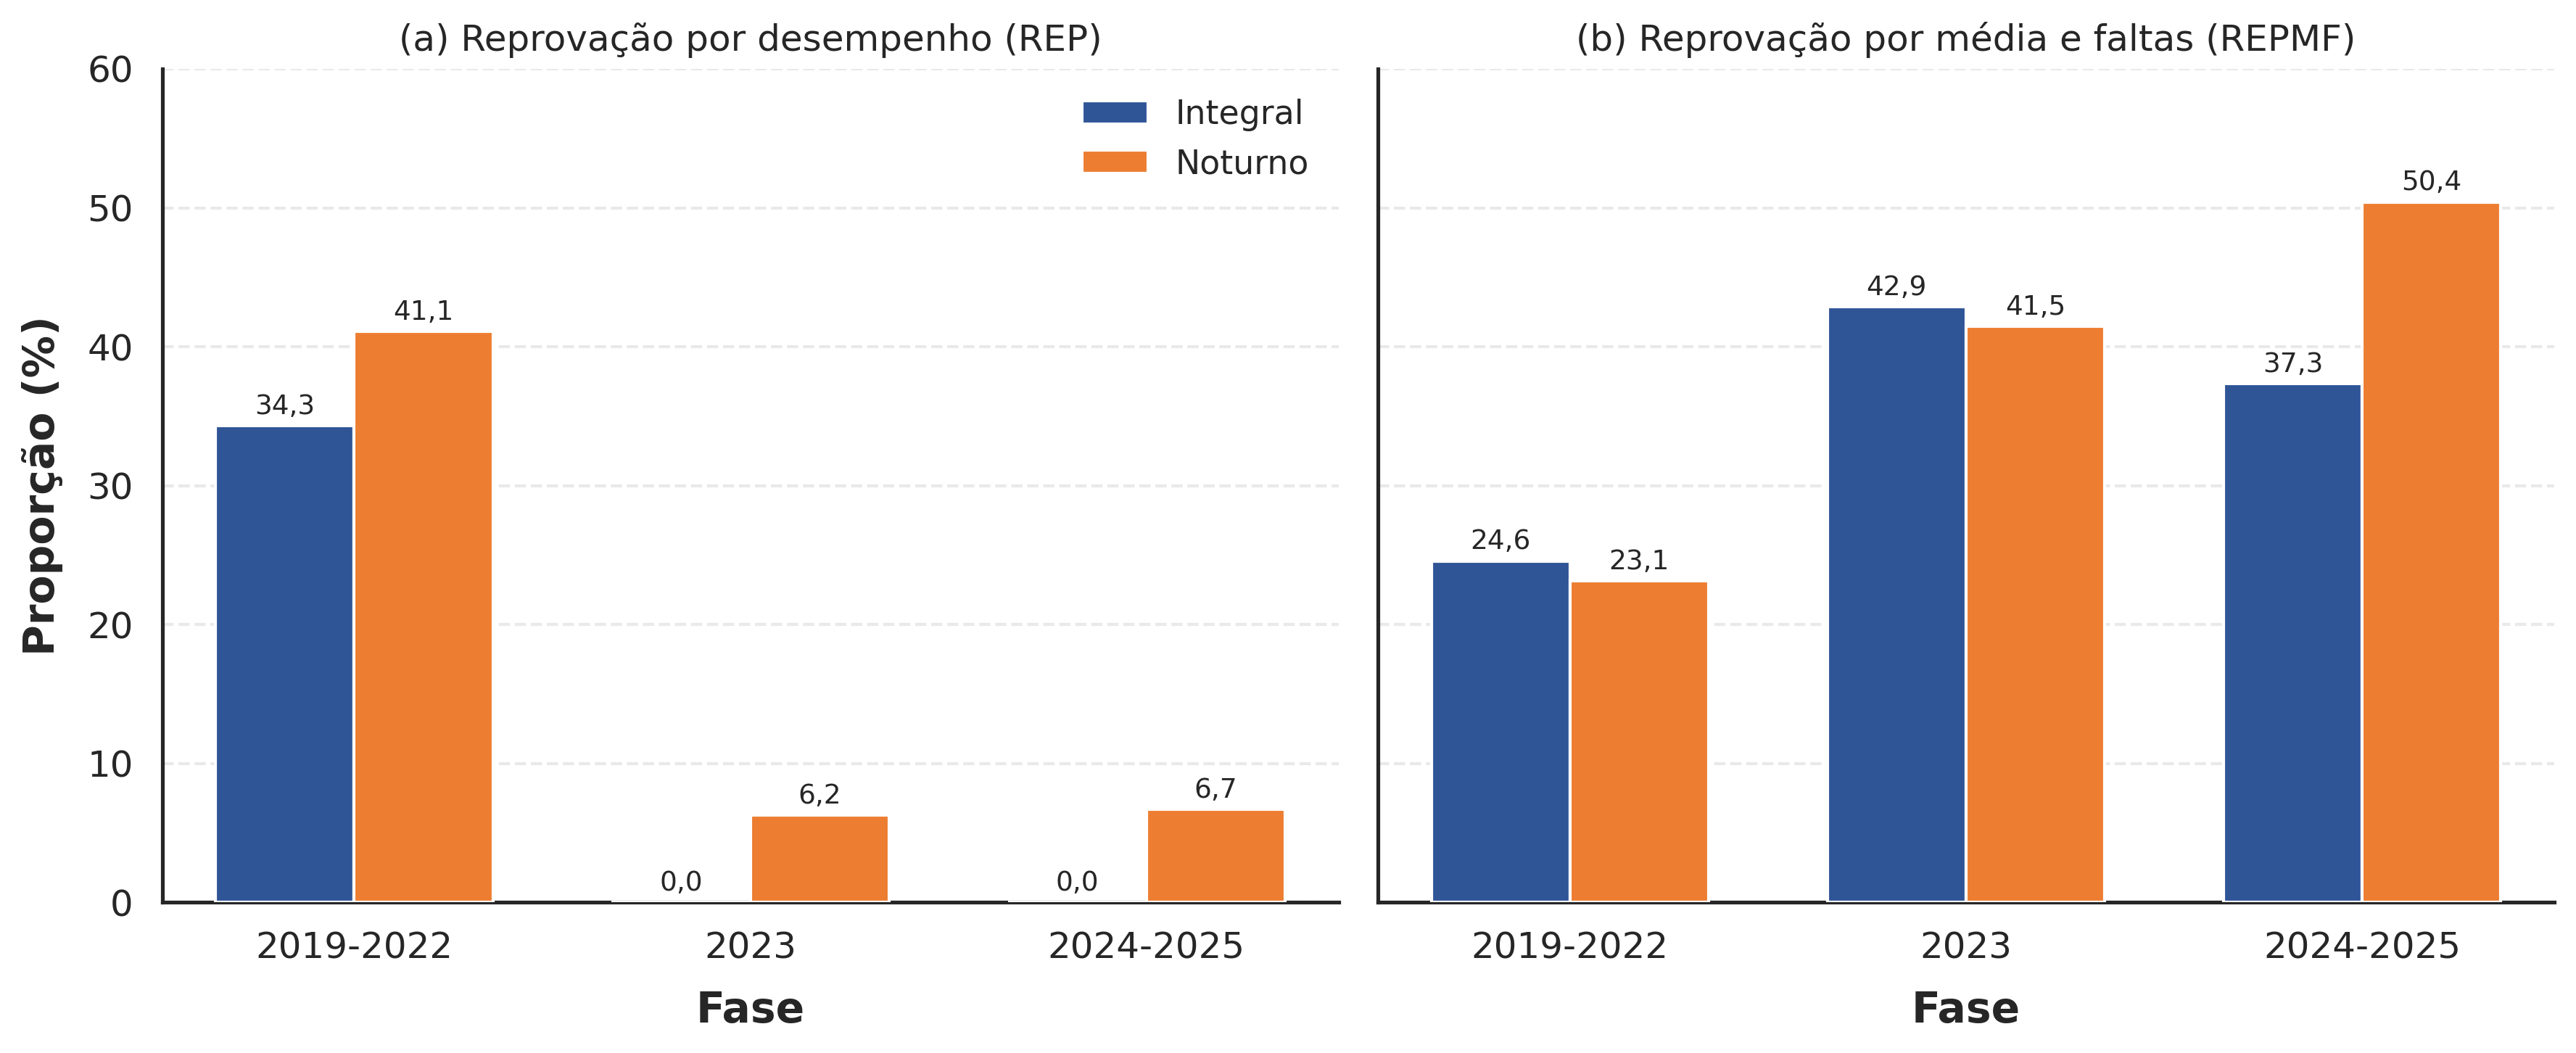

In [45]:
# FIGURA: TAXAS DE REP (entre ativos) E REPMF (sobre o total), POR FASE E TURNO
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

cores = {'Integral': '#2f5597', 'Noturno': '#ed7d31'}
x = np.arange(len(ordem_fases))
largura = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300, sharey=True)
paineis = [('Taxa_REP', '(a) Reprovação por desempenho (REP)'),
           ('Taxa_REPMF', '(b) Reprovação por média e faltas (REPMF)')]

for ax, (col, titulo) in zip(axes, paineis):
    ax.grid(axis='y', linestyle='--', alpha=0.7, color='#e0e0e0', zorder=0)
    for i, turno in enumerate(ordem_turnos):
        vals = df_fase_turno[df_fase_turno['Turno'] == turno].set_index('Periodo').loc[ordem_fases, col]
        barras = ax.bar(x + (i - 0.5) * largura, vals, largura, label=turno, color=cores[turno], zorder=3)
        #ax.bar_label(barras, fmt='%.1f', fontsize=9, padding=2)
        ax.bar_label(barras, labels=[f'{v:.1f}'.replace('.', ',') for v in vals], fontsize=9, padding=2)
    ax.set_title(titulo, fontsize=12)
    ax.set_xticks(x)
    ax.set_xticklabels(ordem_fases)
    ax.set_xlabel('Fase', fontweight='bold', labelpad=8)
    ax.set_ylim(0, 60)

axes[0].set_ylabel('Proporção (%)', fontweight='bold', labelpad=8)
axes[0].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
sns.despine()
plt.tight_layout()

# Salva em formato vetorial para o artigo (Figura: grafico_fase_turno.pdf)
plt.savefig(os.path.join(path, 'grafico_fase_turno.pdf'), format='pdf', bbox_inches='tight')
plt.savefig('grafico_fase_turno.png', format='png', dpi=300, bbox_inches='tight')
path_img = os.path.join(path, 'grafico_fase_turno.png')
plt.savefig(path_img, format='png', dpi=300, bbox_inches='tight')

plt.show()

## Análise de sensibilidade: fase de referência sem os anos remotos (2020 e 2021)

Repete o qui-quadrado, o V de Cramér e o Cochran-Armitage usando apenas os anos de oferta presencial (2019 e 2022) na fase de referência, para verificar se o resultado depende das regras do ensino remoto emergencial.


In [ ]:
# --- ANÁLISE DE SENSIBILIDADE: FASE DE REFERÊNCIA SEM OS ANOS REMOTOS (2020 e 2021) ---
import numpy as np
import scipy.stats as stats

def cochran_armitage(tabela, escores):
    """tabela: linhas = fases ordenadas; colunas = [APR, REP]. Evento = REP."""
    tabela = np.asarray(tabela, dtype=float)
    n = tabela.sum(axis=1); r = tabela[:, 1]; x = np.asarray(escores, dtype=float)
    N = n.sum(); p = r.sum() / N
    num = np.sum(n * x * (r / n - p))
    den = np.sqrt(p * (1 - p) * (np.sum(n * x**2) - np.sum(n * x)**2 / N))
    z = num / den
    return z, 2 * stats.norm.sf(abs(z))

# Exclui 2026 (turmas abertas) e os anos de ensino remoto emergencial (2020 e 2021)
df_sens = df[(df['Ano'] != 2026) & (~df['Ano'].isin([2020, 2021]))].copy()
df_sens['Periodo'] = df_sens['Ano'].apply(mapear_periodo)

tab_sens = (df_sens.groupby('Periodo')[['APR', 'REP']].sum()
            .loc[['2019-2022', '2023', '2024-2025']])
tab_sens['Taxa_REP (%)'] = tab_sens['REP'] / (tab_sens['APR'] + tab_sens['REP']) * 100
print(tab_sens.round(2))
print("(Fase de referência composta apenas por 2019 e 2022)\n")

matriz = tab_sens[['APR', 'REP']].to_numpy()
chi2_s, p_s, gl_s, esp_s = stats.chi2_contingency(matriz)
v_s = np.sqrt(chi2_s / (matriz.sum() * (min(matriz.shape) - 1)))
z_s, pz_s = cochran_armitage(matriz, [1, 2, 3])

print(f"Qui-quadrado: χ² = {chi2_s:.2f}; gl = {gl_s}; p = {p_s:.2e}")
print(f"V de Cramér = {v_s:.3f}; menor frequência esperada = {esp_s.min():.2f}")
print(f"Cochran-Armitage: Z = {z_s:.3f}; p = {pz_s:.2e}")

             APR   REP  Taxa_REP (%)
Periodo                             
2019-2022  111.0  47.0         29.75
2023        77.0   3.0          3.75
2024-2025   98.0   4.0          3.92
(Fase de referência composta apenas por 2019 e 2022)

Qui-quadrado: χ² = 42.47; gl = 2; p = 6.00e-10
V de Cramér = 0.353; menor frequência esperada = 12.71
Cochran-Armitage: Z = -5.892; p = 3.81e-09
